# **Import**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/dog_adoption_master.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 32 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   adoption_id             42000 non-null  object 
 1   age_years               42000 non-null  float64
 2   size                    42000 non-null  object 
 3   weight_kg               42000 non-null  float64
 4   breed_group             42000 non-null  object 
 5   intake_type             42000 non-null  object 
 6   days_in_shelter         42000 non-null  int64  
 7   previously_returned     42000 non-null  int64  
 8   medical_needs           42000 non-null  object 
 9   neutered                42000 non-null  int64  
 10  aggression_score        42000 non-null  float64
 11  anxiety_separation      42000 non-null  float64
 12  reactivity_to_dogs      42000 non-null  float64
 13  energy_level            42000 non-null  float64
 14  training_level          42000 non-null

# **Preprocessing**

In [ ]:
print(df.describe())
df.head(10)

          age_years     weight_kg  days_in_shelter  previously_returned  \
count  42000.000000  42000.000000     42000.000000         42000.000000   
mean       3.799564     20.269795        35.765524             0.112452   
std        2.667531     12.159154        27.369866             0.315926   
min        0.200000      2.000000         1.000000             0.000000   
25%        1.800000      8.900000        16.000000             0.000000   
50%        3.200000     18.800000        29.000000             0.000000   
75%        5.200000     28.700000        49.000000             0.000000   
max       16.000000     70.600000       350.000000             1.000000   

           neutered  aggression_score  anxiety_separation  reactivity_to_dogs  \
count  42000.000000      42000.000000        42000.000000        42000.000000   
mean       0.928595          2.522829            4.054836            3.499693   
std        0.257503          1.851998            2.168071            2.219308   


,adoption_id,age_years,size,weight_kg,breed_group,intake_type,days_in_shelter,previously_returned,medical_needs,neutered,...,adopter_activity_level,visits_before_adoption,met_resident_pets,adoption_counseling,expectation_score,energy_mismatch,size_home_mismatch,return_reason,days_to_return,returned
0,ADP000000,2.6,small,7.2,mixed,stray,51,0,none,1,...,2.6,1,0,0,7.3,1.4,0,kept,NaN,0
1,ADP000001,5.4,large,27.9,sporting,stray,38,1,none,1,...,3.8,1,0,0,6.2,4.2,0,kept,NaN,0
2,ADP000002,3.5,medium,15.4,mixed,owner_surrender,14,0,none,1,...,1.1,1,0,0,8.1,3.5,0,kept,NaN,0
3,ADP000003,7.3,medium,23.2,working,stray,9,0,none,1,...,7.8,3,0,1,10.0,0.8,0,unmet_expectations,4.5,1
4,ADP000004,0.7,medium,16.2,mixed,stray,35,1,minor,1,...,3.6,1,0,0,7.9,6.4,0,aggression,12.9,1
5,ADP000005,4.9,medium,14.5,working,stray,44,0,none,1,...,6.1,2,1,1,6.6,0.4,0,kept,NaN,0
6,ADP000006,6.8,medium,19.4,herding,stray,27,0,none,1,...,5.1,3,0,0,5.0,0.7,0,kept,NaN,0
7,ADP000007,4.7,large,30.6,working,owner_surrender,7,0,none,1,...,5.6,1,0,0,5.2,0.7,0,kept,NaN,0
8,ADP000008,4.4,large,25.2,mixed,stray,20,0,none,1,...,3.5,1,0,0,8.2,5.9,1,kept,NaN,0
9,ADP000009,4.9,small,8.7,terrier,stray,40,0,minor,1,...,5.0,1,0,0,5.2,0.3,0,kept,NaN,0


In [ ]:
strdf = df.select_dtypes(include=['object', 'string'])
print("Unique values in original string/object columns:")
print(pd.DataFrame(strdf.nunique(), columns=['Unique Values']))

# Apply the mapping to the 'size' column in the main DataFrame
size_mapping = {'small': 1, 'medium': 2, 'large': 3, 'xlarge': 4}

df['size'] = df['size'].map(size_mapping)


# Convert the 'size' column to integer type
df['size'] = df['size'].astype(int)


# Display the new value counts for the modified 'size' column
print("\nValue counts column after mapping:")
print(df['size'].value_counts())

Unique values in original string/object columns:
               Unique Values
adoption_id            42000
size                       4
breed_group                7
intake_type                4
medical_needs              3
home_type                  3
return_reason             10

Value counts column after mapping:
size
2    14380
1    12505
3    11719
4     3396
Name: count, dtype: int64


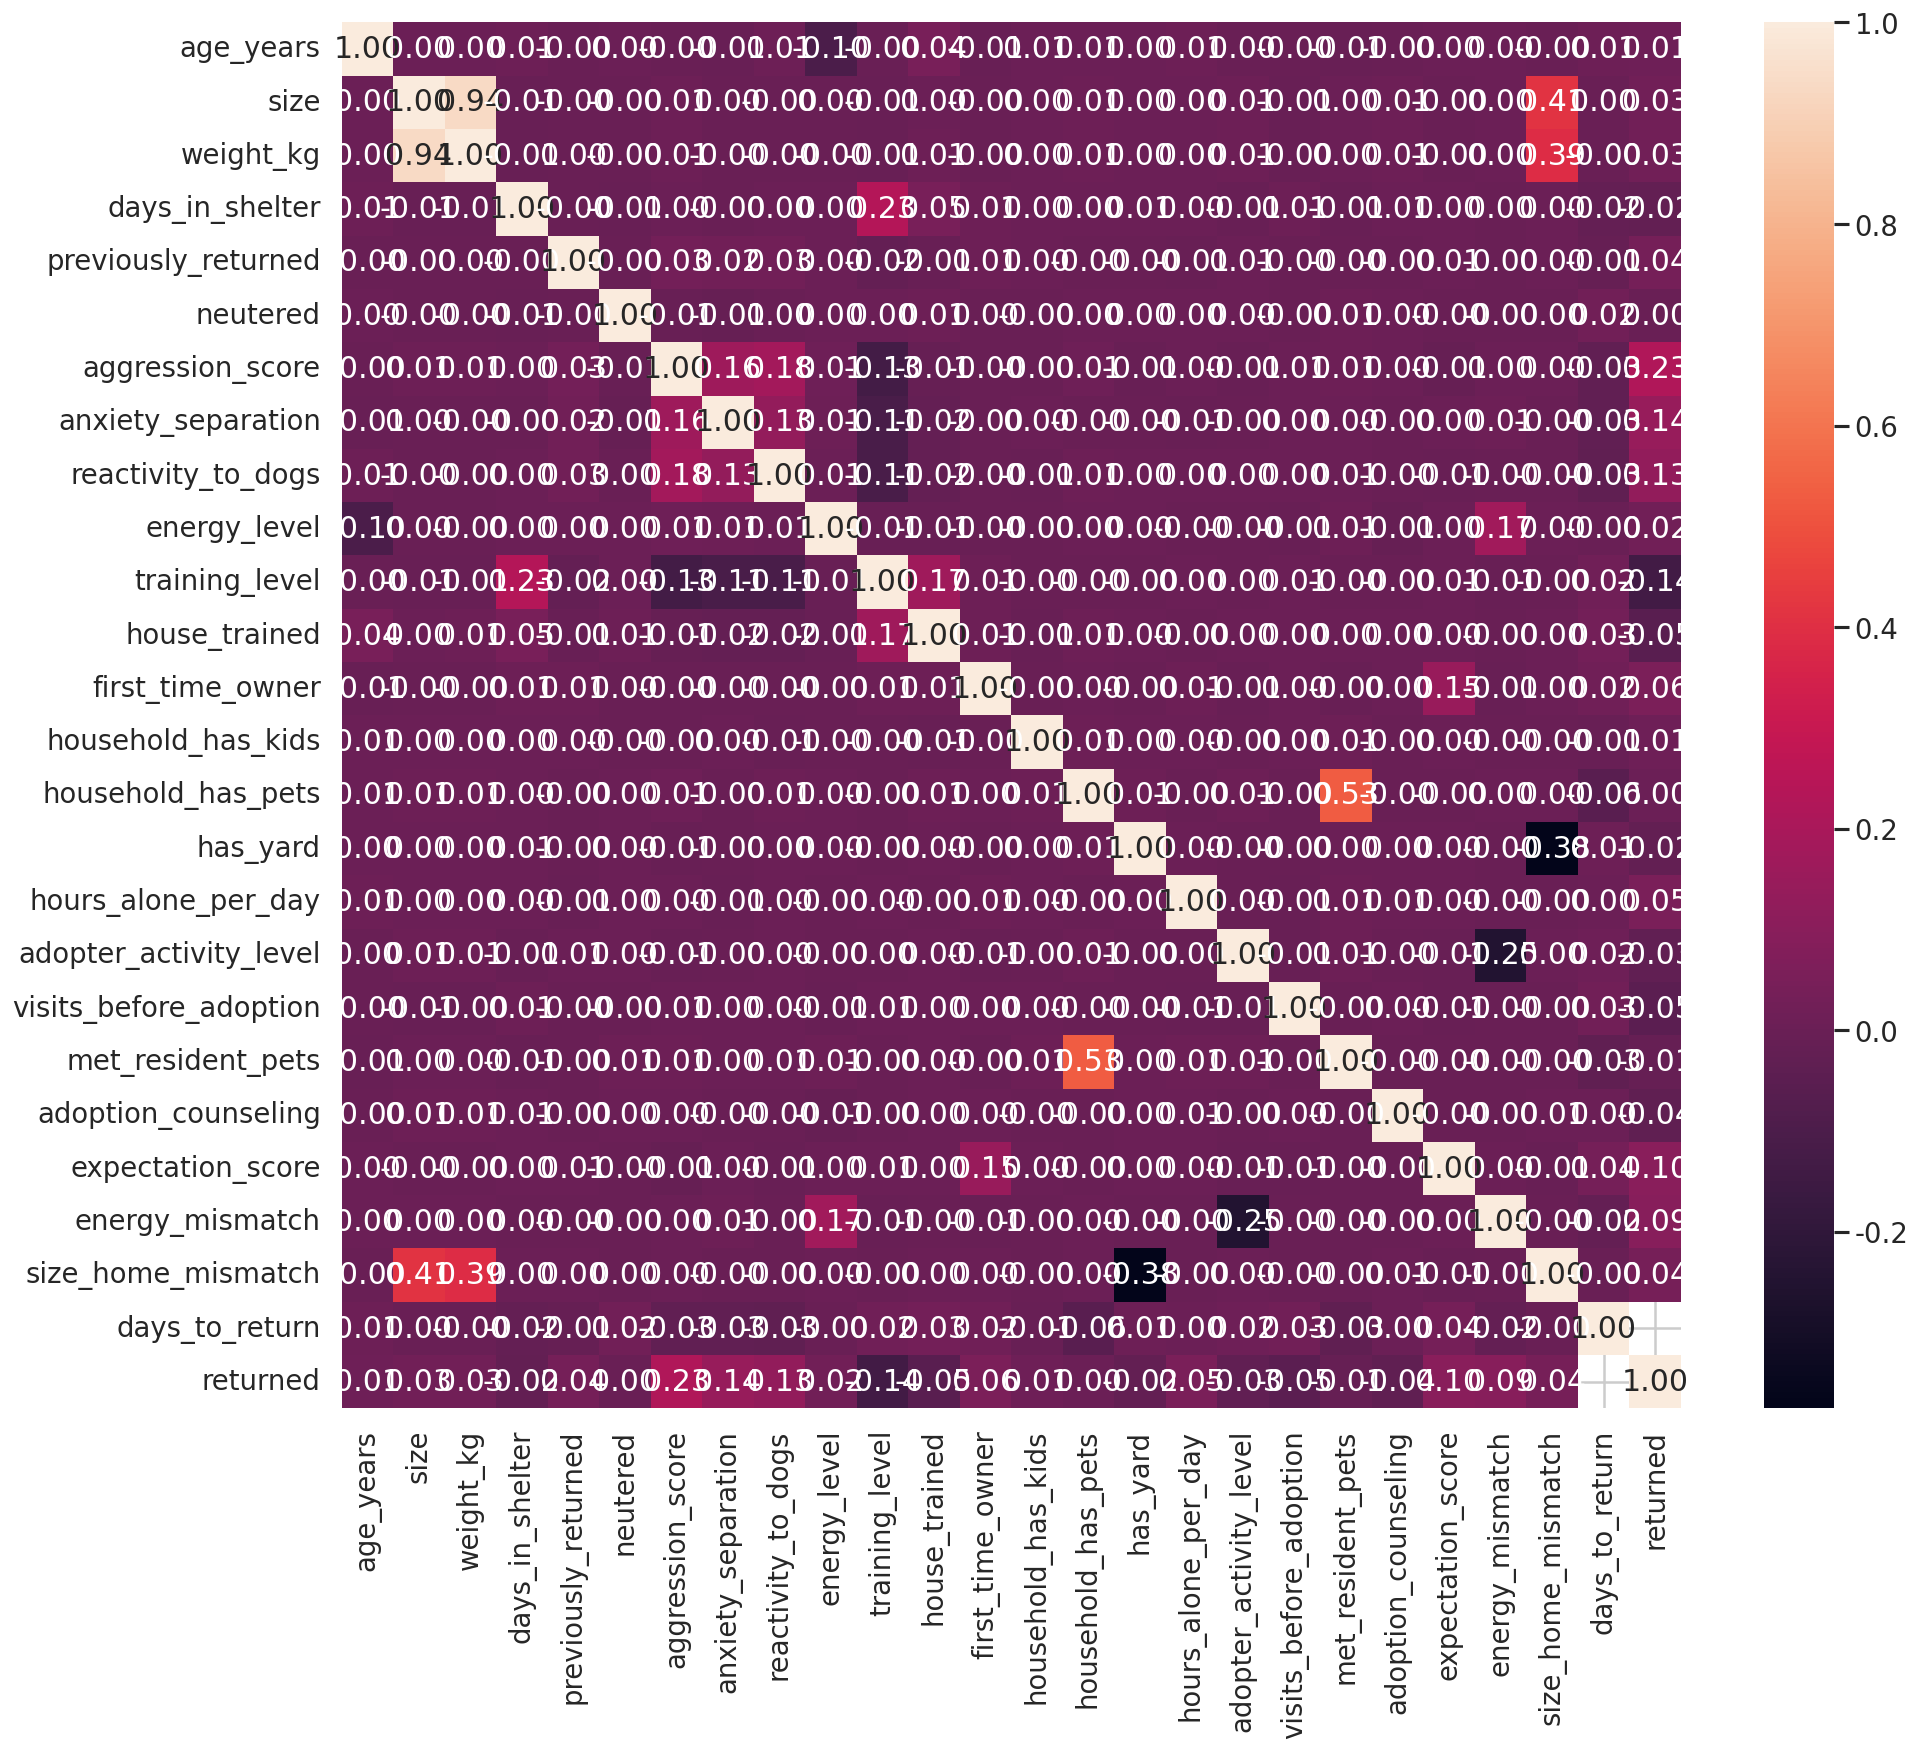

In [ ]:
plt.figure(figsize=(18,15))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f')
plt.show()

In [ ]:
# Drop features that were not used in visualizations or had zero impact score
# and remove temporary binned columns used for plotting

cols_to_drop = [
    'adoption_id',           # Identifier
    'neutered',              # Near zero impact
    'days_in_shelter',       # Low impact
    'success',               # Derived target (inverse of returned)
    'outcome',               # Categorical label for returned
    'age_years'
    'weight_kg',
    'breed_group',
    'intake_type',
    'previously_returned',
    'neutered',
    'house_trained',
    'household_has_kids',
    'has_yard',
    'adopter_activity_level'
    'visits_before_adoption'
]

# Drop columns if they exist in the dataframe
df_cleaned = df.drop(columns=[c for c in cols_to_drop if c in df.columns])

print(f"Original columns: {len(df.columns)}")
print(f"Cleaned columns: {len(df_cleaned.columns)}")
print("\nRemaining features:")
print(df_cleaned.columns.tolist())

# Keep the cleaned dataframe as the main df
df = df_cleaned


Original columns: 32
Cleaned columns: 23

Remaining features:
['age_years', 'size', 'weight_kg', 'medical_needs', 'aggression_score', 'anxiety_separation', 'reactivity_to_dogs', 'energy_level', 'training_level', 'first_time_owner', 'household_has_pets', 'home_type', 'hours_alone_per_day', 'adopter_activity_level', 'visits_before_adoption', 'met_resident_pets', 'adoption_counseling', 'expectation_score', 'energy_mismatch', 'size_home_mismatch', 'return_reason', 'days_to_return', 'returned']


In [ ]:
# Drop specific features as requested
df = df.drop(columns=['weight_kg', 'age_years','visits_before_adoption','adopter_activity_level', 'size_home_mismatch'], errors='ignore')

print("Updated columns:")
print(df.columns.tolist())

Updated columns:
['size', 'medical_needs', 'aggression_score', 'anxiety_separation', 'reactivity_to_dogs', 'energy_level', 'training_level', 'first_time_owner', 'household_has_pets', 'home_type', 'hours_alone_per_day', 'met_resident_pets', 'adoption_counseling', 'expectation_score', 'energy_mismatch', 'return_reason', 'days_to_return', 'returned']


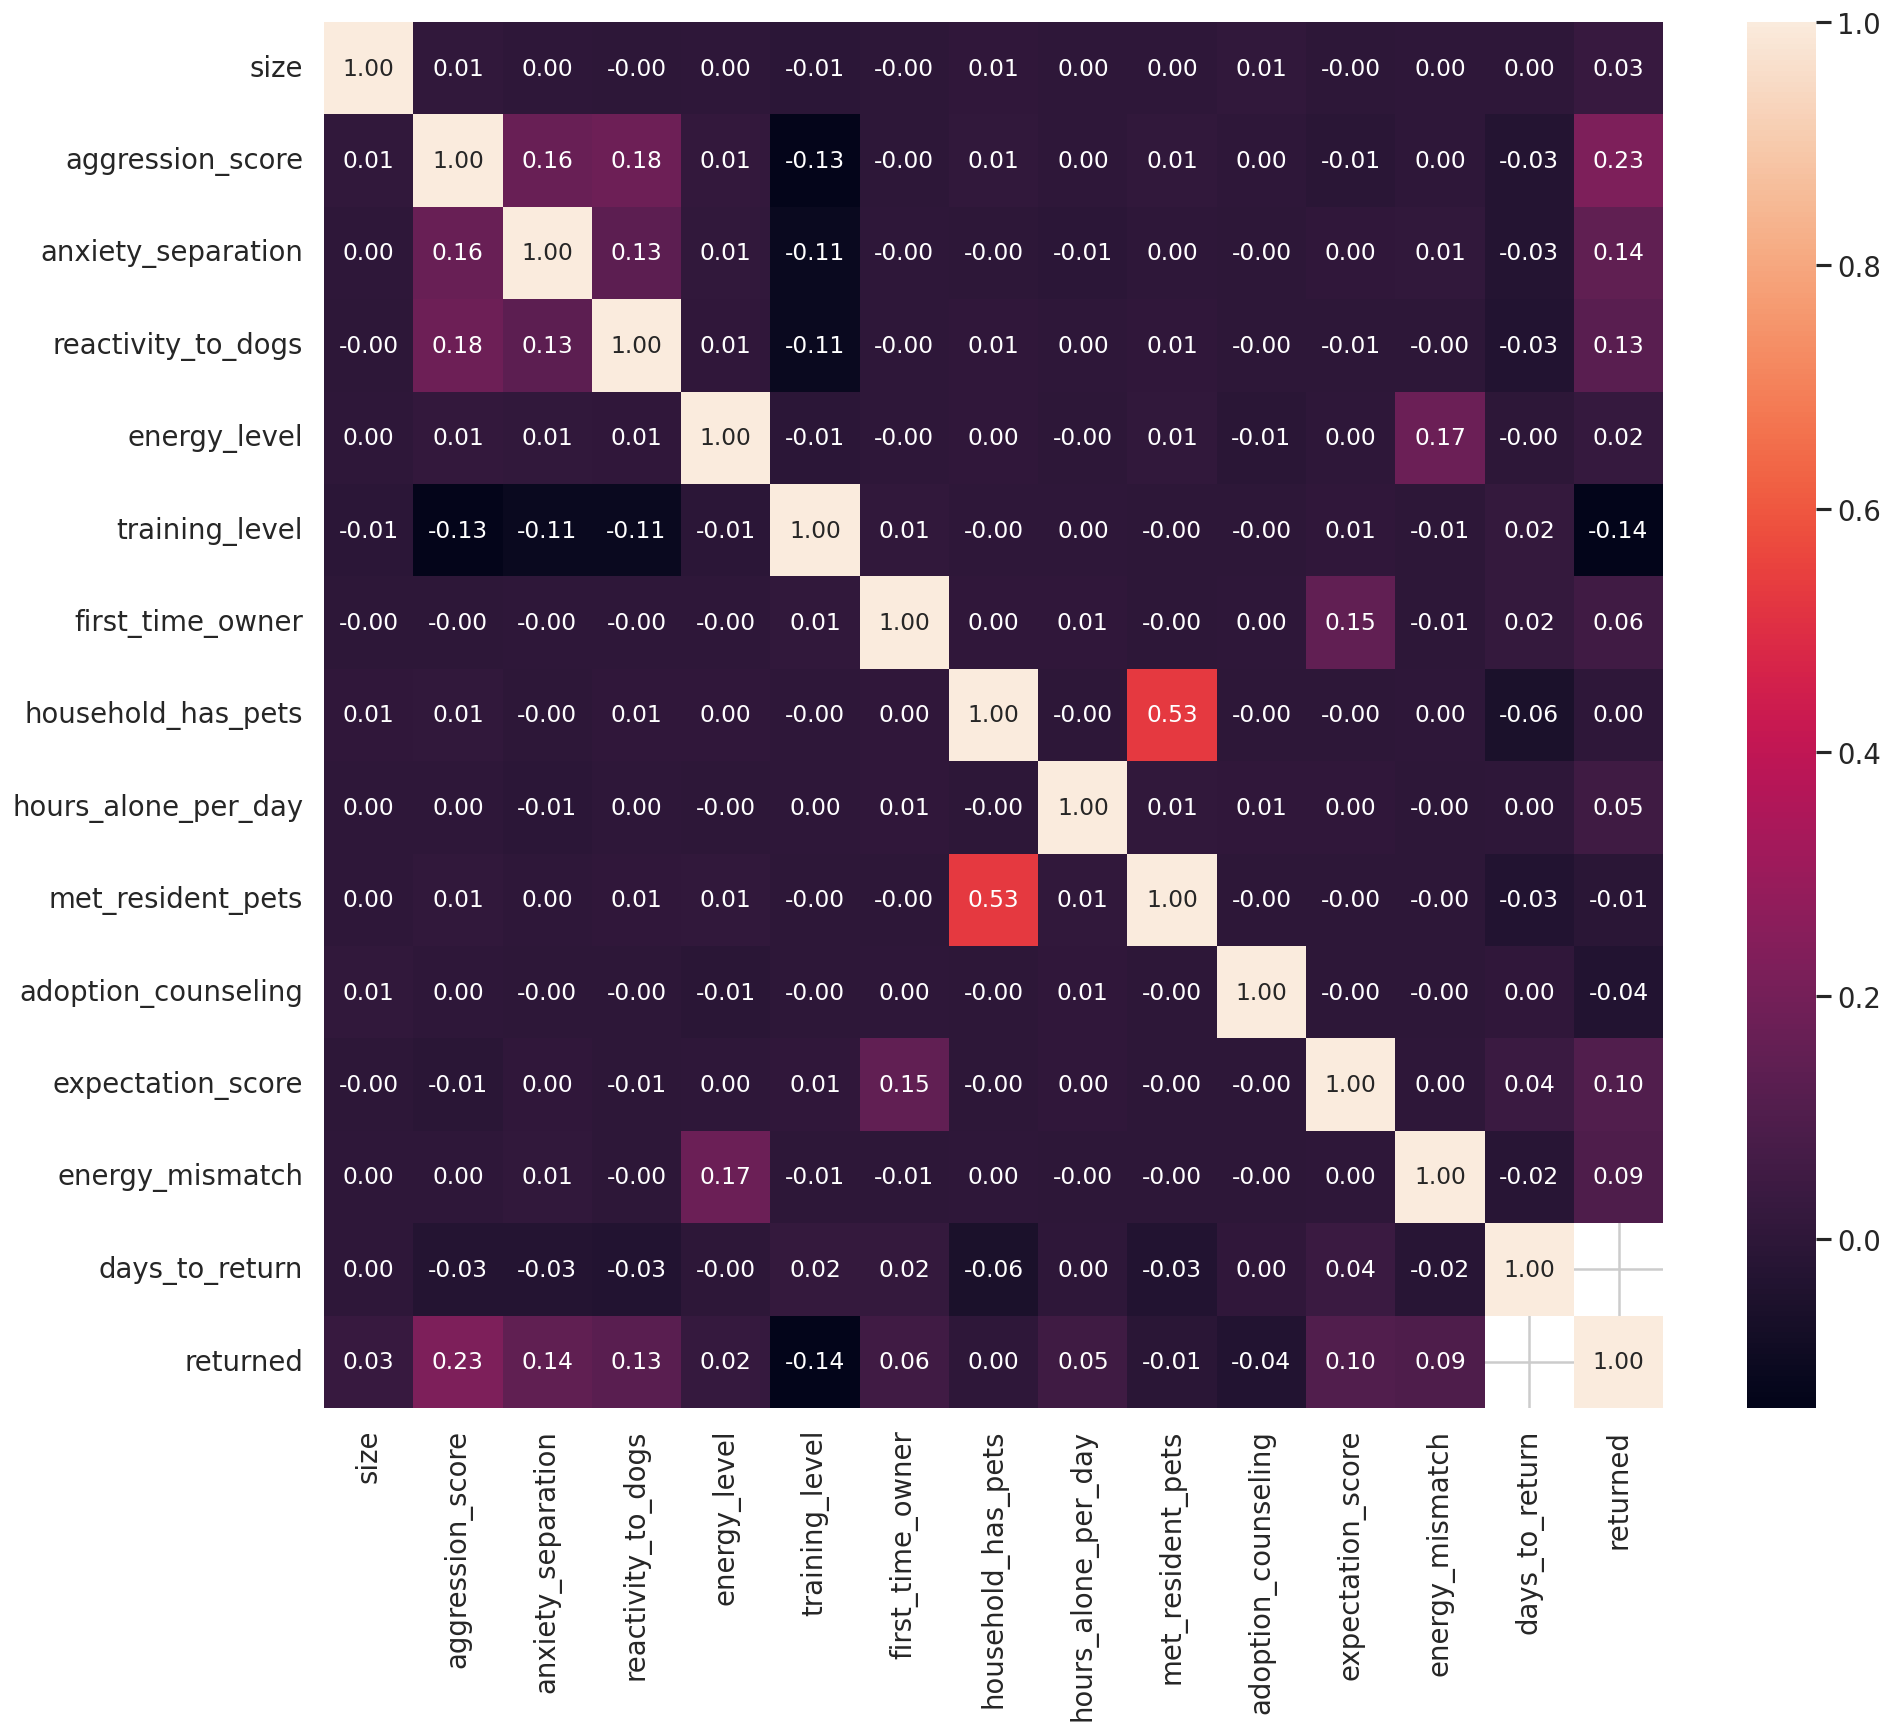

In [ ]:
plt.figure(figsize=(18,15))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt='.2f', annot_kws={"size":14})
plt.show()

In [ ]:
def detect_outliers_iqr(df, features=None):

    """

    หา outlier ด้วยวิธี IQR ในแต่ละ feature

    คืนค่าเป็น dict บอกจำนวน/ index ของ outlier แต่ละ feature

    """

    if features is None:

        features = df.select_dtypes(include=[np.number]).columns.tolist()



    outlier_summary = {}



    for col in features:

        Q1 = df[col].quantile(0.25)

        Q3 = df[col].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR

        upper_bound = Q3 + 1.5 * IQR



        outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]



        outlier_summary[col] = {

            'count': len(outliers),

            'percentage': round(len(outliers) / len(df) * 100, 2),

            'lower_bound': lower_bound,

            'upper_bound': upper_bound,

            'outlier_index': outliers.index.tolist()

        }



    return outlier_summary


# ตัวอย่างการใช้งาน

# df = pd.read_csv('your_data.csv')

result = detect_outliers_iqr(df)


for col, info in result.items():

    print(f"Feature: {col}")

    print(f"  Outlier count: {info['count']} ({info['percentage']}%)")

    print(f"  Bounds: [{info['lower_bound']:.2f}, {info['upper_bound']:.2f}]")

    print("-" * 40)

Feature: size
  Outlier count: 0 (0.0%)
  Bounds: [-2.00, 6.00]
----------------------------------------
Feature: aggression_score
  Outlier count: 142 (0.34%)
  Bounds: [-3.20, 8.00]
----------------------------------------
Feature: anxiety_separation
  Outlier count: 0 (0.0%)
  Bounds: [-2.00, 10.00]
----------------------------------------
Feature: reactivity_to_dogs
  Outlier count: 147 (0.35%)
  Bounds: [-3.00, 9.80]
----------------------------------------
Feature: energy_level
  Outlier count: 168 (0.4%)
  Bounds: [0.75, 11.55]
----------------------------------------
Feature: training_level
  Outlier count: 0 (0.0%)
  Bounds: [-1.50, 11.30]
----------------------------------------
Feature: first_time_owner
  Outlier count: 0 (0.0%)
  Bounds: [-1.50, 2.50]
----------------------------------------
Feature: household_has_pets
  Outlier count: 0 (0.0%)
  Bounds: [-1.50, 2.50]
----------------------------------------
Feature: hours_alone_per_day
  Outlier count: 0 (0.0%)
  Bounds: [

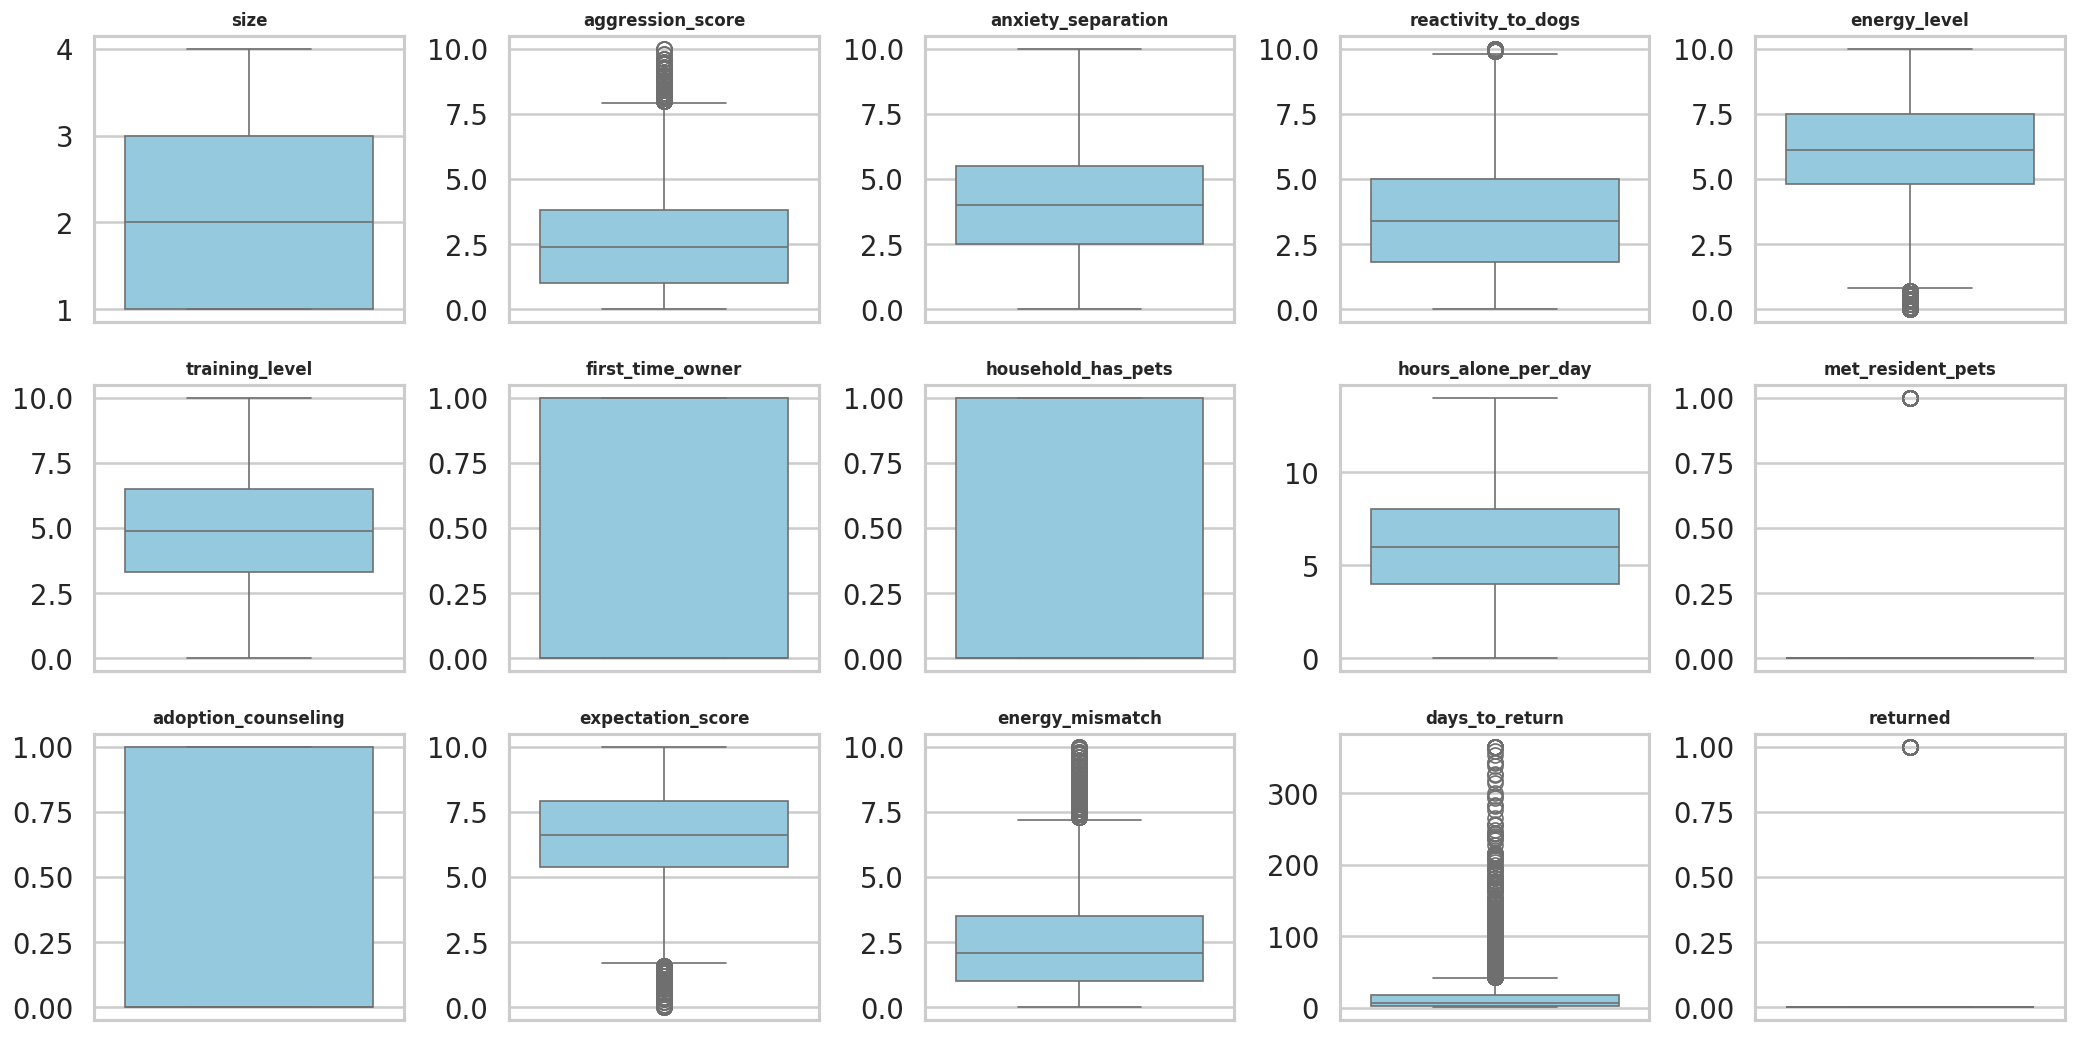

In [ ]:
def plot_all_boxplots(df, features, ncols=5):
    n = len(features)
    nrows = int(np.ceil(n / ncols))

    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(ncols*3.5, nrows*3))
    axes = axes.flatten()

    for i, col in enumerate(features):
        sns.boxplot(y=df[col], ax=axes[i], color='skyblue')
        axes[i].set_title(col, fontsize=10)
        axes[i].set_xlabel('')
        axes[i].set_ylabel('')

    # ซ่อนช่องว่างที่เหลือ
    for j in range(i+1, len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.savefig('boxplots_all_features.png', dpi=150)
    plt.show()

# Define features as all numerical columns for plotting
features = df.select_dtypes(include=[np.number]).columns.tolist()
# Exclude 'adoption_id' if it's a number but represents an identifier
if 'adoption_id' in features:
    features.remove('adoption_id')

plot_all_boxplots(df, features)

/tmp/ipykernel_3429/1298089982.py:26: UserWarning: Glyph 3648 (\N{THAI CHARACTER SARA E}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3429/1298089982.py:26: UserWarning: Glyph 3611 (\N{THAI CHARACTER PO PLA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3429/1298089982.py:26: UserWarning: Glyph 3629 (\N{THAI CHARACTER O ANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3429/1298089982.py:26: UserWarning: Glyph 3619 (\N{THAI CHARACTER RO RUA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3429/1298089982.py:26: UserWarning: Glyph 3660 (\N{THAI CHARACTER THANTHAKHAT}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3429/1298089982.py:26: UserWarning: Glyph 3595 (\N{THAI CHARACTER SO SO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3429/1298089982.py:26: UserWarning: Glyph 3655 (\N{THAI CHARACTER MAITAIKHU}) missing from font(s) DejaVu Sans.


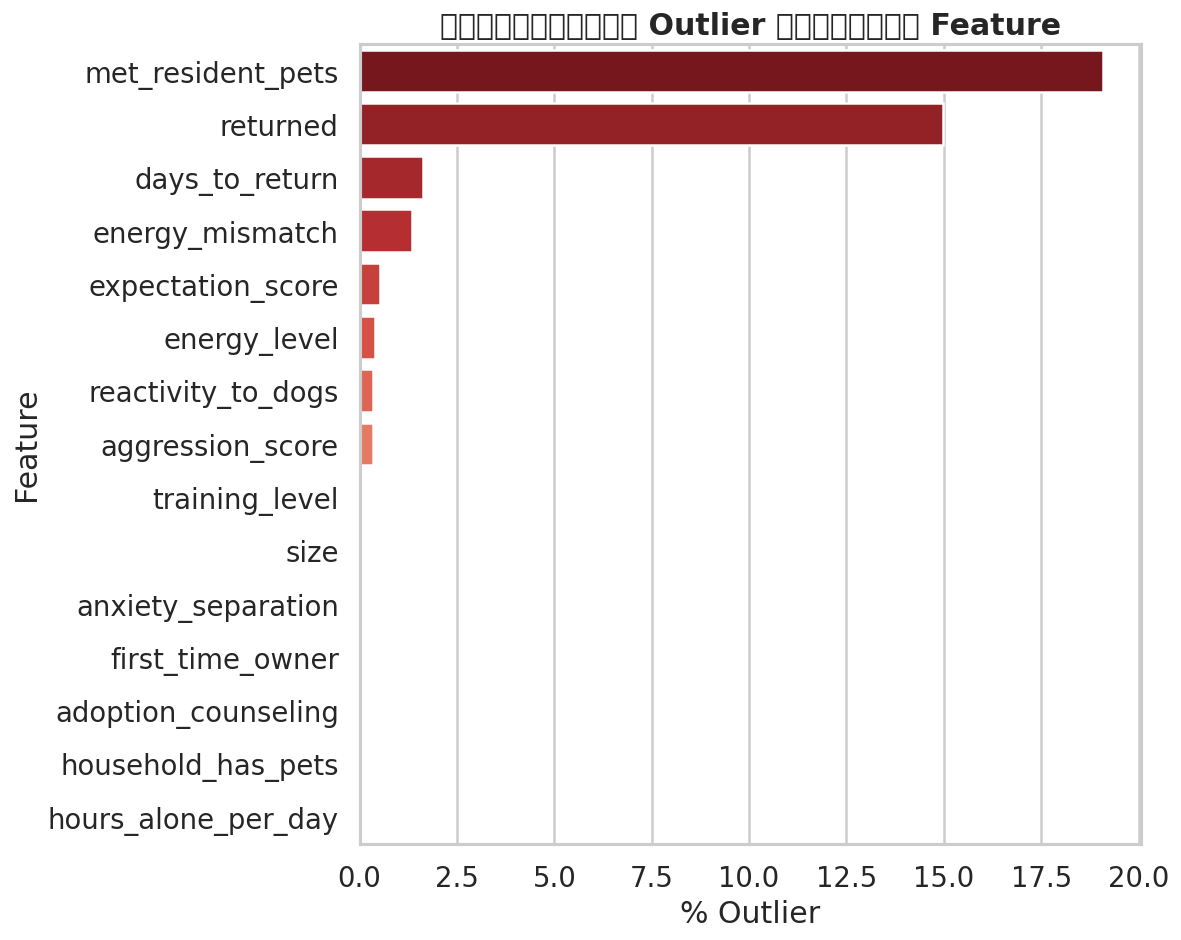

In [ ]:
import matplotlib.font_manager as fm

# Add a Thai font to Matplotlib's font manager
# This is a common font available in Colab, but other Thai fonts can be used.
font_path = '/usr/share/fonts/truetype/th_sarabun_new/THSarabunNew.ttf'
if fm.findfont('TH Sarabun New', rebuild_if_missing=False) is None:
    fm.fontManager.addfont(font_path)

# Configure Matplotlib to use the Thai font
plt.rcParams['font.family'] = 'TH Sarabun New'
plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False # To correctly display minus signs

outlier_data = []
for col, info in result.items():
    outlier_data.append({'feature': col, 'outlier_pct': info['percentage']})

outlier_report = pd.DataFrame(outlier_data)
outlier_report = outlier_report.sort_values(by='outlier_pct', ascending=False)

plt.figure(figsize=(10, 8))
sns.barplot(data=outlier_report, x='outlier_pct', y='feature', hue='feature', palette='Reds_r', legend=False)
plt.xlabel('% Outlier')
plt.ylabel('Feature')
plt.title('เปอร์เซ็นต์ Outlier ของแต่ละ Feature')
plt.tight_layout()
plt.savefig('outlier_percentage_summary.png', dpi=150)
plt.show()

In [ ]:
count_greater_than_140 = df[df['days_to_return'] > 40].shape[0]
print(f"Number of values in 'days_to_return' greater than 350: {count_greater_than_140}")

Number of values in 'days_to_return' greater than 350: 734


In [ ]:
df[df['days_to_return'] > 140]

,size,medical_needs,aggression_score,anxiety_separation,reactivity_to_dogs,energy_level,training_level,first_time_owner,household_has_pets,home_type,hours_alone_per_day,met_resident_pets,adoption_counseling,expectation_score,energy_mismatch,return_reason,days_to_return,returned
734,2,none,6.2,6.6,5.6,4.9,4.5,0,0,house_owned,9.7,0,0,6.5,3.7,other,313.9,1
792,1,none,1.4,6.5,0.0,5.3,8.1,1,0,apartment,8.7,0,0,8.3,0.9,housing_landlord,149.2,1
985,2,minor,3.1,6.3,5.0,8.9,4.1,0,1,apartment,10.4,0,1,9.5,5.7,allergies,365.0,1
1114,3,minor,6.2,6.0,2.1,3.4,0.8,1,1,house_owned,3.1,0,0,9.2,4.0,housing_landlord,365.0,1
1116,3,none,0.0,3.4,3.9,6.6,3.6,0,1,apartment,7.3,1,0,6.2,1.4,housing_landlord,365.0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41112,3,minor,4.7,3.0,5.8,4.0,7.8,1,0,house_owned,2.3,0,0,5.6,2.9,separation_anxiety_destruction,181.6,1
41260,4,none,1.3,5.9,1.9,3.3,2.2,1,0,apartment,4.9,0,1,7.9,0.0,housing_landlord,365.0,1
41473,2,none,4.4,2.3,3.3,8.2,4.8,1,1,house_rented,2.1,0,1,7.8,1.1,allergies,365.0,1
41615,3,minor,1.5,4.0,4.4,3.7,6.2,0,1,house_owned,2.7,0,0,4.9,1.6,cost_time,365.0,1


In [ ]:

# 1. คำนวณหาค่ามัธยฐาน (Median) ของฟีเจอร์นั้น (คำนวณจากข้อมูลทั้งหมดในคอลัมน์)
median_day_return = df['days_to_return'].median()

# 2. ค้นหาค่าที่มากกว่า 350 และแทนที่ด้วยค่ามัธยฐานที่คำนวณได้
df.loc[df['days_to_return'] > 40, 'days_to_return'] = median_day_return


# **Visualization**

Overall Adoption Success Rate: 85.0%
            feature    impact
   aggression_score 20.251676
 anxiety_separation 13.464528
     training_level 12.822355
 reactivity_to_dogs 11.539310
  expectation_score  9.208931
    energy_mismatch  8.162099
hours_alone_per_day  4.422928
   first_time_owner  4.116454
       energy_level  3.074331
               size  2.933567
adoption_counseling  2.689241
  met_resident_pets  1.125042
 household_has_pets  0.084156
     days_to_return  0.000000


/tmp/ipykernel_3429/1249775485.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(bins)['success'].mean() * 100
/tmp/ipykernel_3429/1249775485.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(bins)['success'].mean() * 100
/tmp/ipykernel_3429/1249775485.py:57: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = df.groupby(bins)['success'].mean() * 100
/tmp/ipykernel_3429/12497

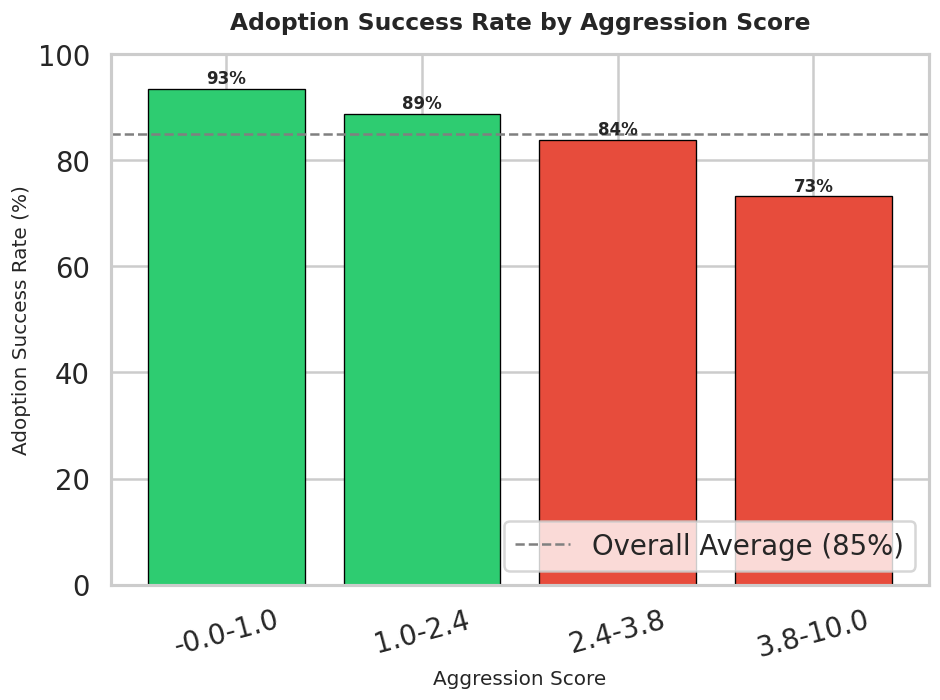

/tmp/ipykernel_3429/1249775485.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


✔ Saved: success_rate_plots/01_success_rate_by_aggression_score.png


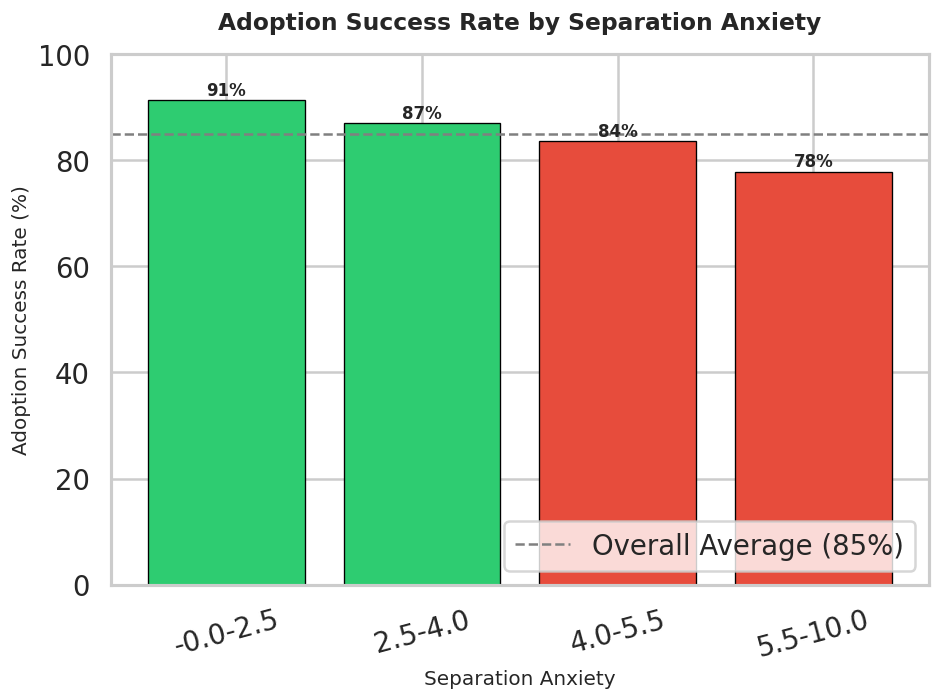

/tmp/ipykernel_3429/1249775485.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


✔ Saved: success_rate_plots/02_success_rate_by_anxiety_separation.png


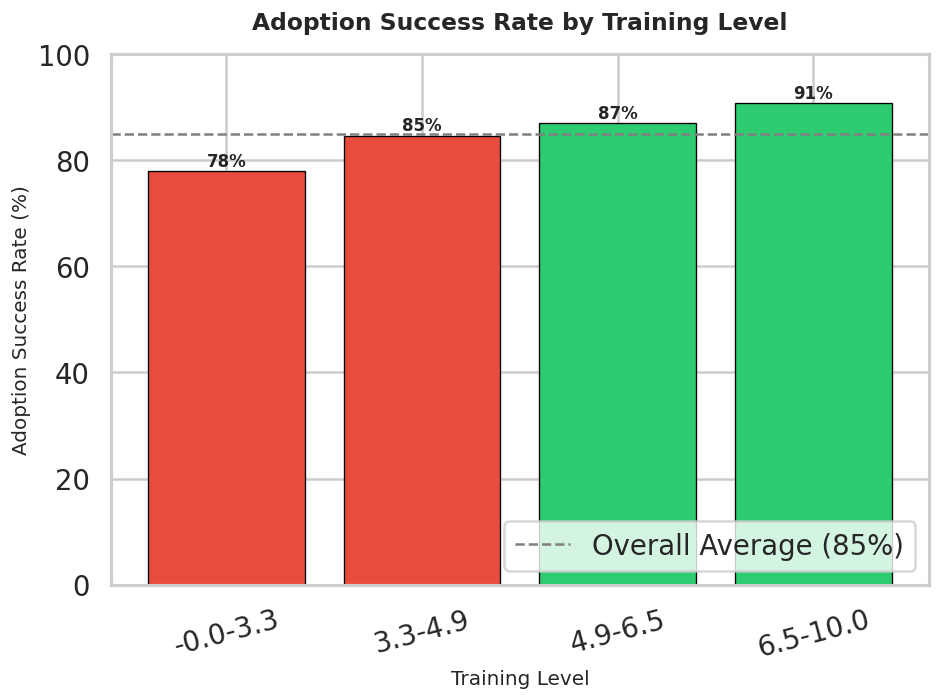

/tmp/ipykernel_3429/1249775485.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


✔ Saved: success_rate_plots/03_success_rate_by_training_level.png


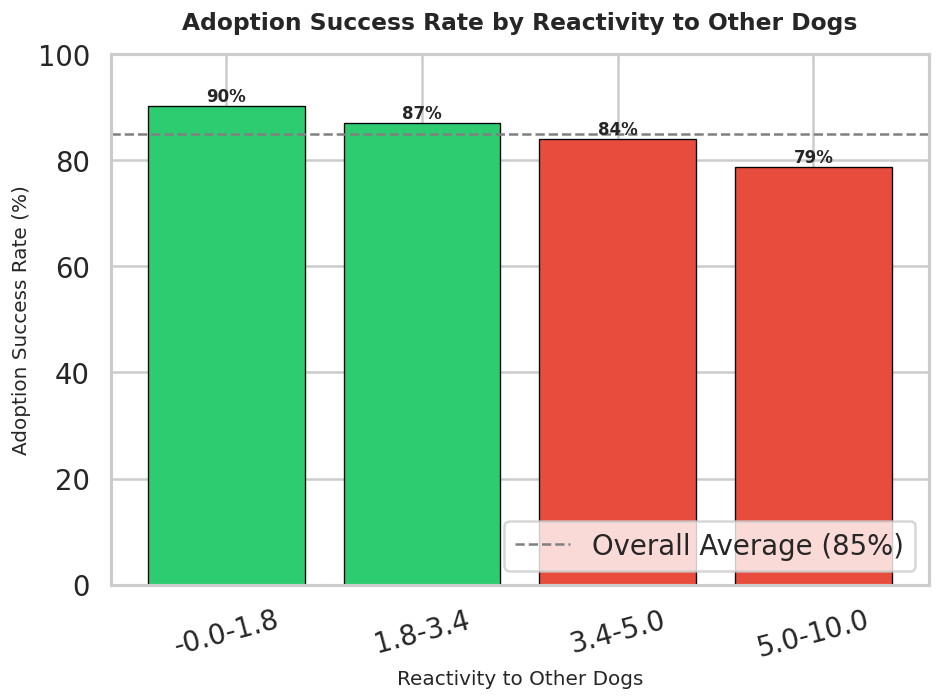

/tmp/ipykernel_3429/1249775485.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


✔ Saved: success_rate_plots/04_success_rate_by_reactivity_to_dogs.png


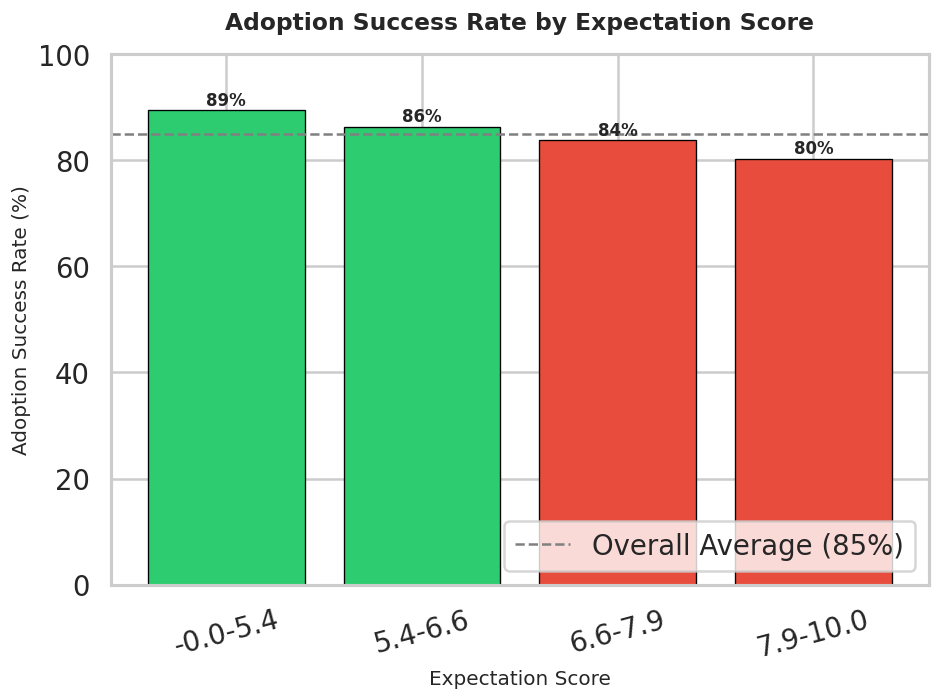

/tmp/ipykernel_3429/1249775485.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


✔ Saved: success_rate_plots/05_success_rate_by_expectation_score.png


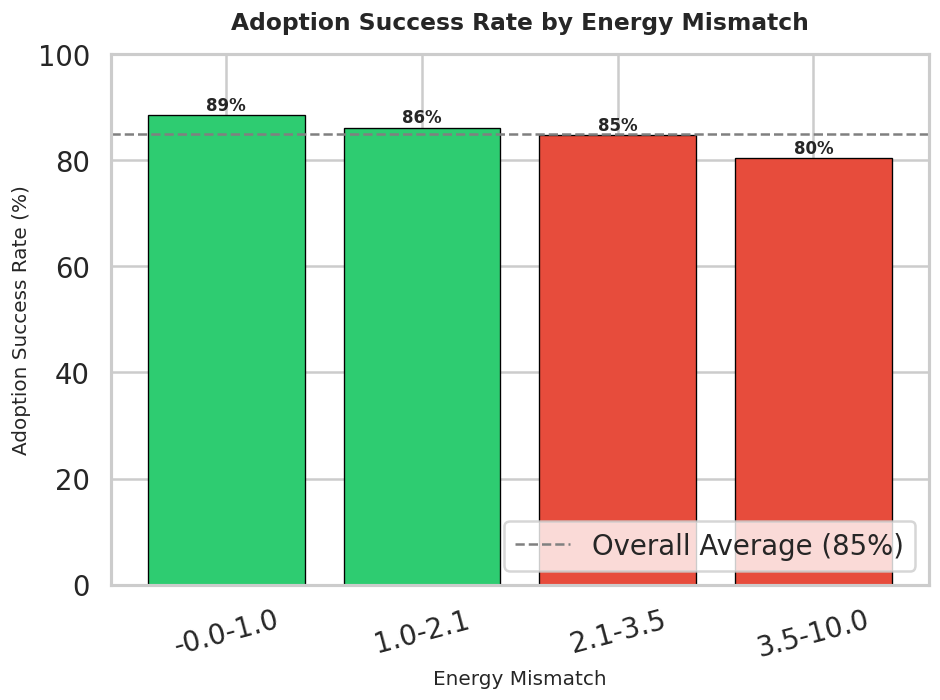

/tmp/ipykernel_3429/1249775485.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


✔ Saved: success_rate_plots/06_success_rate_by_energy_mismatch.png


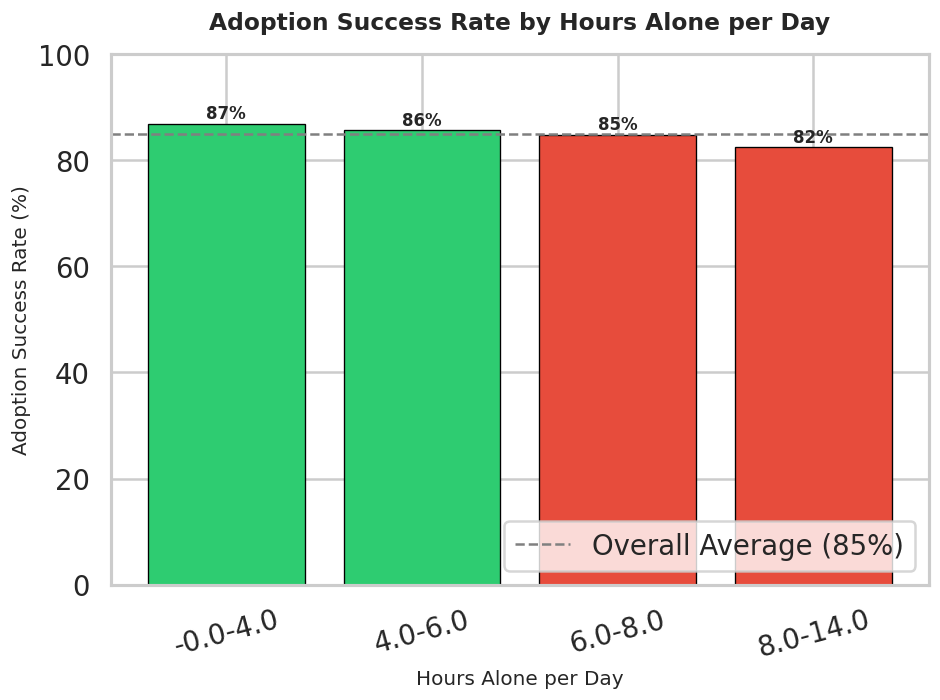

✔ Saved: success_rate_plots/07_success_rate_by_hours_alone_per_day.png


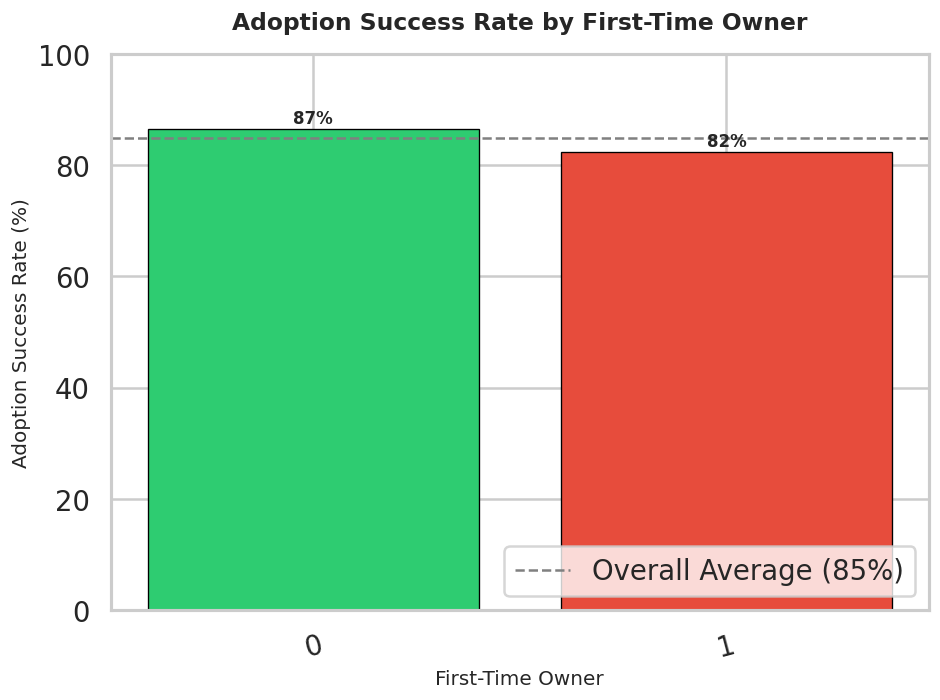

/tmp/ipykernel_3429/1249775485.py:75: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rates = (df.groupby(bins)['success'].mean() * 100)


✔ Saved: success_rate_plots/08_success_rate_by_first_time_owner.png


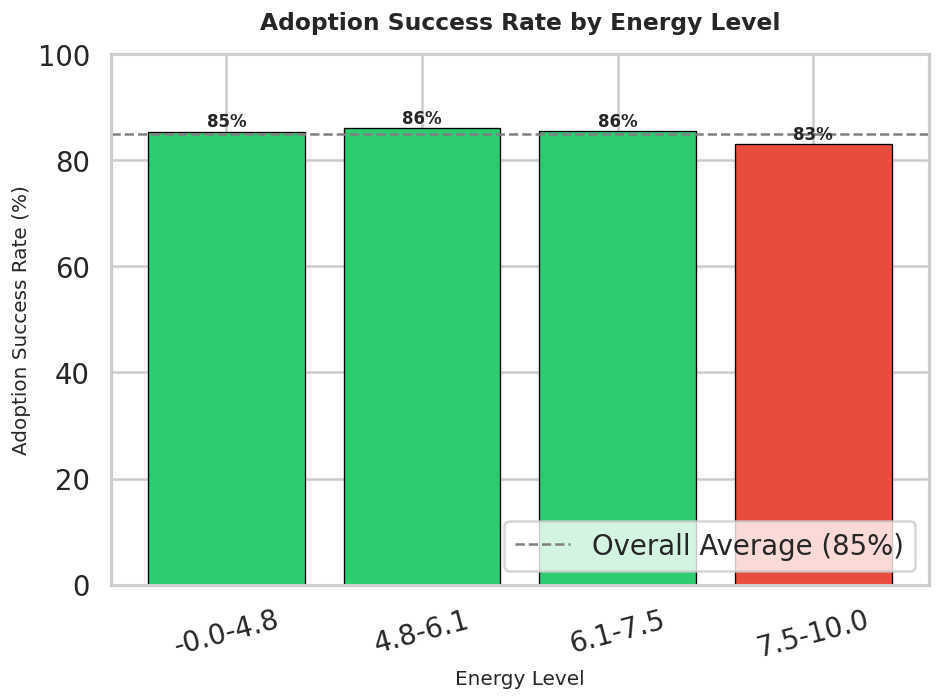

✔ Saved: success_rate_plots/09_success_rate_by_energy_level.png


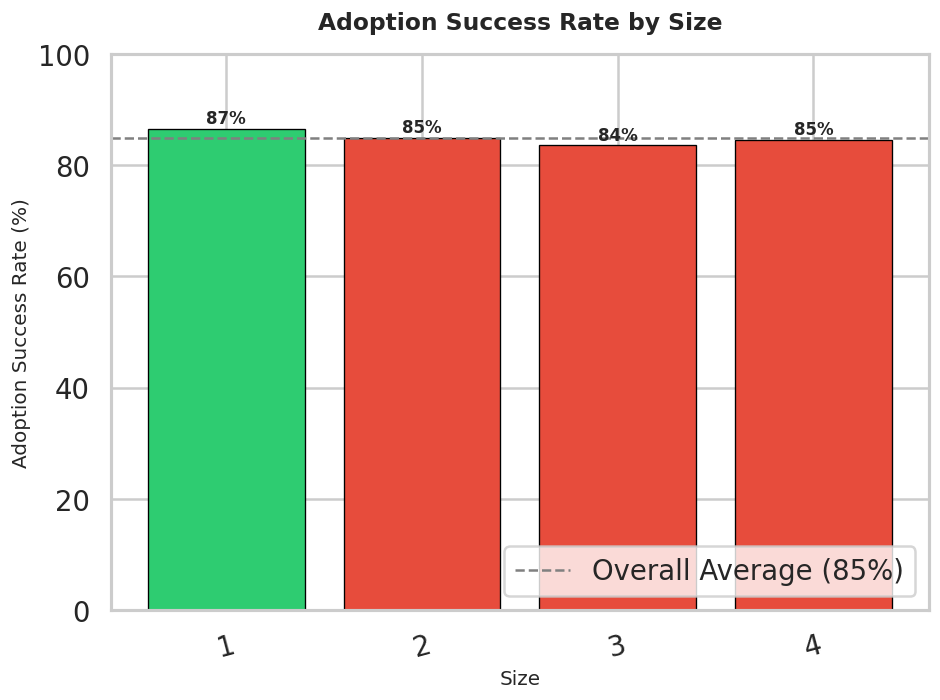

✔ Saved: success_rate_plots/10_success_rate_by_size.png


In [ ]:
import os

output_dir = 'success_rate_plots'
os.makedirs(output_dir, exist_ok=True)

# ---------- 1. สร้างคอลัมน์ success (ตรงข้ามกับ returned) ----------
df['success'] = 1 - df['returned']
overall_success_rate = df['success'].mean() * 100
print(f"Overall Adoption Success Rate: {overall_success_rate:.1f}%")

# ---------- 2. Label map ภาษาอังกฤษ ----------
label_map = {
    'age_years': 'Age (years)',
    'size': 'Size',
    'weight_kg': 'Weight (kg)',
    'days_in_shelter': 'Days in Shelter',
    'previously_returned': 'Previously Returned',
    'neutered': 'Neutered',
    'aggression_score': 'Aggression Score',
    'anxiety_separation': 'Separation Anxiety',
    'reactivity_to_dogs': 'Reactivity to Other Dogs',
    'energy_level': 'Energy Level',
    'training_level': 'Training Level',
    'house_trained': 'House Trained',
    'first_time_owner': 'First-Time Owner',
    'household_has_kids': 'Household Has Kids',
    'household_has_pets': 'Household Has Other Pets',
    'has_yard': 'Has Yard',
    'hours_alone_per_day': 'Hours Alone per Day',
    'adopter_activity_level': 'Adopter Activity Level',
    'visits_before_adoption': 'Pre-Adoption Visits',
    'met_resident_pets': 'Met Resident Pets Before',
    'adoption_counseling': 'Received Adoption Counseling',
    'expectation_score': 'Expectation Score',
    'energy_mismatch': 'Energy Mismatch',
    'size_home_mismatch': 'Size-Home Mismatch',
}

def get_label(col):
    return label_map.get(col, col.replace('_', ' ').title())

def is_discrete(series, max_unique=6):
    return series.nunique() <= max_unique

# ---------- 3. หาฟีเจอร์ที่มีผลต่อ success rate มากที่สุด ----------
features = [c for c in df.select_dtypes(include=[np.number]).columns
            if c not in ['returned', 'success']]

impact_scores = []
for col in features:
    if is_discrete(df[col]):
        rates = df.groupby(col)['success'].mean() * 100
        impact = rates.max() - rates.min()
    else:
        # แบ่งเป็น bin 4 กลุ่ม (quartile)
        bins = pd.qcut(df[col], 4, duplicates='drop')
        rates = df.groupby(bins)['success'].mean() * 100
        impact = rates.max() - rates.min()
    impact_scores.append((col, impact))

impact_df = pd.DataFrame(impact_scores, columns=['feature', 'impact']).sort_values('impact', ascending=False)
print(impact_df.to_string(index=False))

# ---------- 4. วาดกราฟ Success Rate แยกทีละ feature ----------
top_n = 10  # เลือกเฉพาะ 10 ฟีเจอร์ที่มีผลมากที่สุด
for i, row in impact_df.head(top_n).iterrows():
    col = row['feature']
    fig, ax = plt.subplots(figsize=(8, 6))

    if is_discrete(df[col]):
        rates = (df.groupby(col)['success'].mean() * 100).sort_index()
        x_labels = [str(x) for x in rates.index]
    else:
        bins = pd.qcut(df[col], 4, duplicates='drop')
        rates = (df.groupby(bins)['success'].mean() * 100)
        x_labels = [f"{b.left:.1f}-{b.right:.1f}" for b in rates.index]

    colors = ['#2ecc71' if v >= overall_success_rate else '#e74c3c' for v in rates.values]
    bars = ax.bar(x_labels, rates.values, color=colors, edgecolor='black', linewidth=0.8)

    # เส้น benchmark ค่าเฉลี่ยรวม
    ax.axhline(overall_success_rate, color='gray', linestyle='--', linewidth=1.5,
               label=f'Overall Average ({overall_success_rate:.0f}%)')

    # ใส่ตัวเลข % บนแท่งกราฟ
    for bar, v in zip(bars, rates.values):
        ax.text(bar.get_x() + bar.get_width()/2, v + 1, f'{v:.0f}%',
                ha='center', fontsize=10, fontweight='bold')

    ax.set_ylim(0, 100)
    ax.set_ylabel('Adoption Success Rate (%)', fontsize=12)
    ax.set_xlabel(get_label(col), fontsize=12)
    ax.set_title(f'Adoption Success Rate by {get_label(col)}', fontsize=14, fontweight='bold', pad=15)
    ax.legend(loc='lower right')
    plt.xticks(rotation=15)
    plt.tight_layout()

    rank = impact_df.index.get_loc(i) + 1
    filename = f"{output_dir}/{rank:02d}_success_rate_by_{col}.png"
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f"✔ Saved: {filename}")

In [ ]:
# ============================================================
# Dog Adoption Success — Does the Match Last?
# Exploratory Data Visualization for Presentation
# ============================================================
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"

PALETTE = {"kept": "#2E86AB", "returned": "#E4572E"}
SEQ = "RdYlBu_r"

df["outcome"] = np.where(df["returned"] == 1, "Returned", "Stayed Home")

def show(fig, name):
    fig.savefig(f"{name}.png")
    plt.show()

def rate_by(col, min_n=30):
    """Return-rate table by a categorical column."""
    g = (df.groupby(col)["returned"]
           .agg(return_rate=lambda s: s.mean() * 100, n="size")
           .query("n >= @min_n")
           .sort_values("return_rate"))
    return g

BASE = df["returned"].mean() * 100   # 15.3%

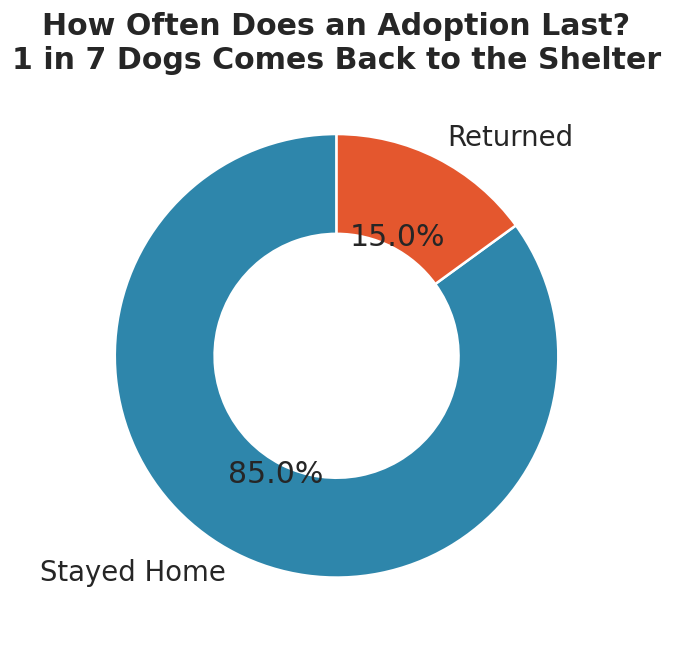

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
counts = df["outcome"].value_counts()
ax.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90,
       colors=[PALETTE["kept"], PALETTE["returned"]],
       wedgeprops=dict(width=0.45, edgecolor="white"))
ax.set_title("How Often Does an Adoption Last?\n1 in 7 Dogs Comes Back to the Shelter")
show(fig, "01_overall_outcome")


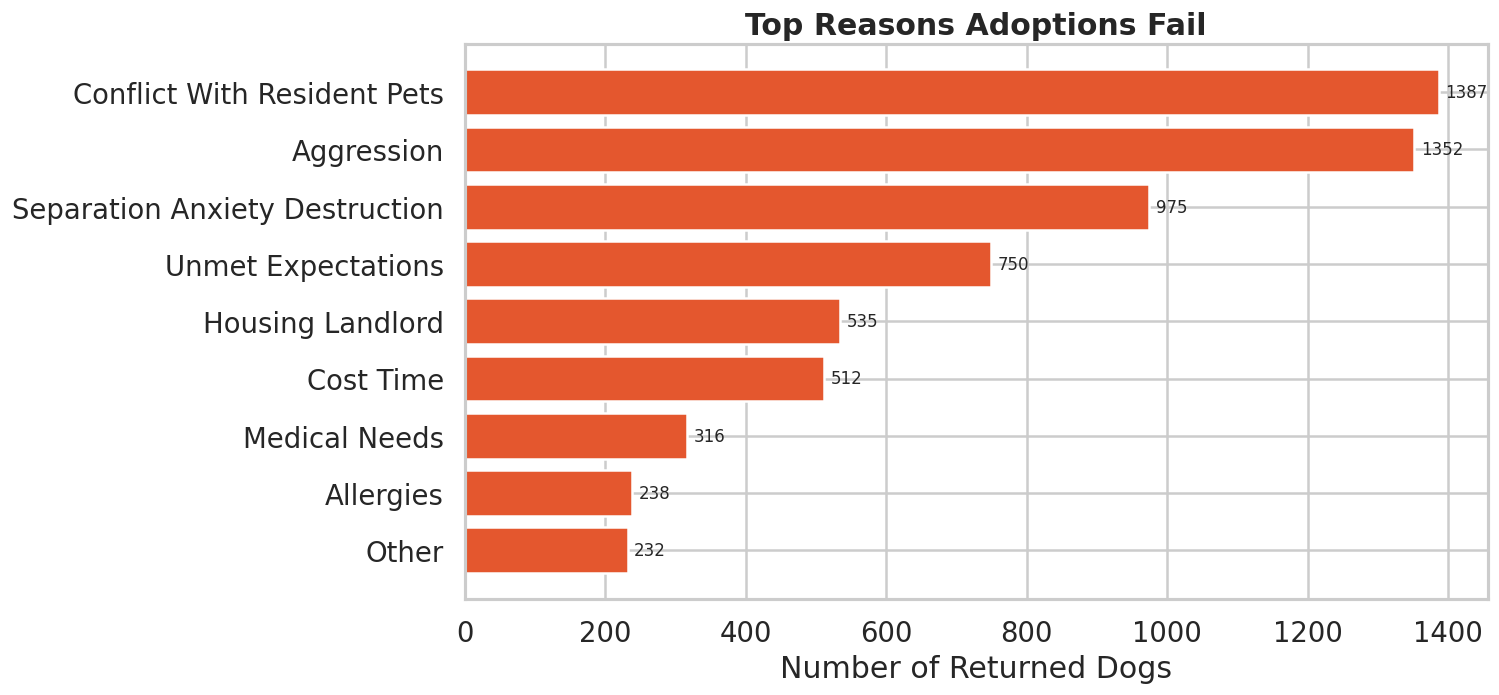

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))
reasons = (df.loc[df["returned"] == 1, "return_reason"]
             .value_counts().sort_values())
reasons.index = reasons.index.str.replace("_", " ").str.title()
bars = ax.barh(reasons.index, reasons.values, color=PALETTE["returned"])
ax.bar_label(bars, padding=4, fontsize=10)
ax.set_xlabel("Number of Returned Dogs")
ax.set_title("Top Reasons Adoptions Fail")
show(fig, "02_return_reasons")

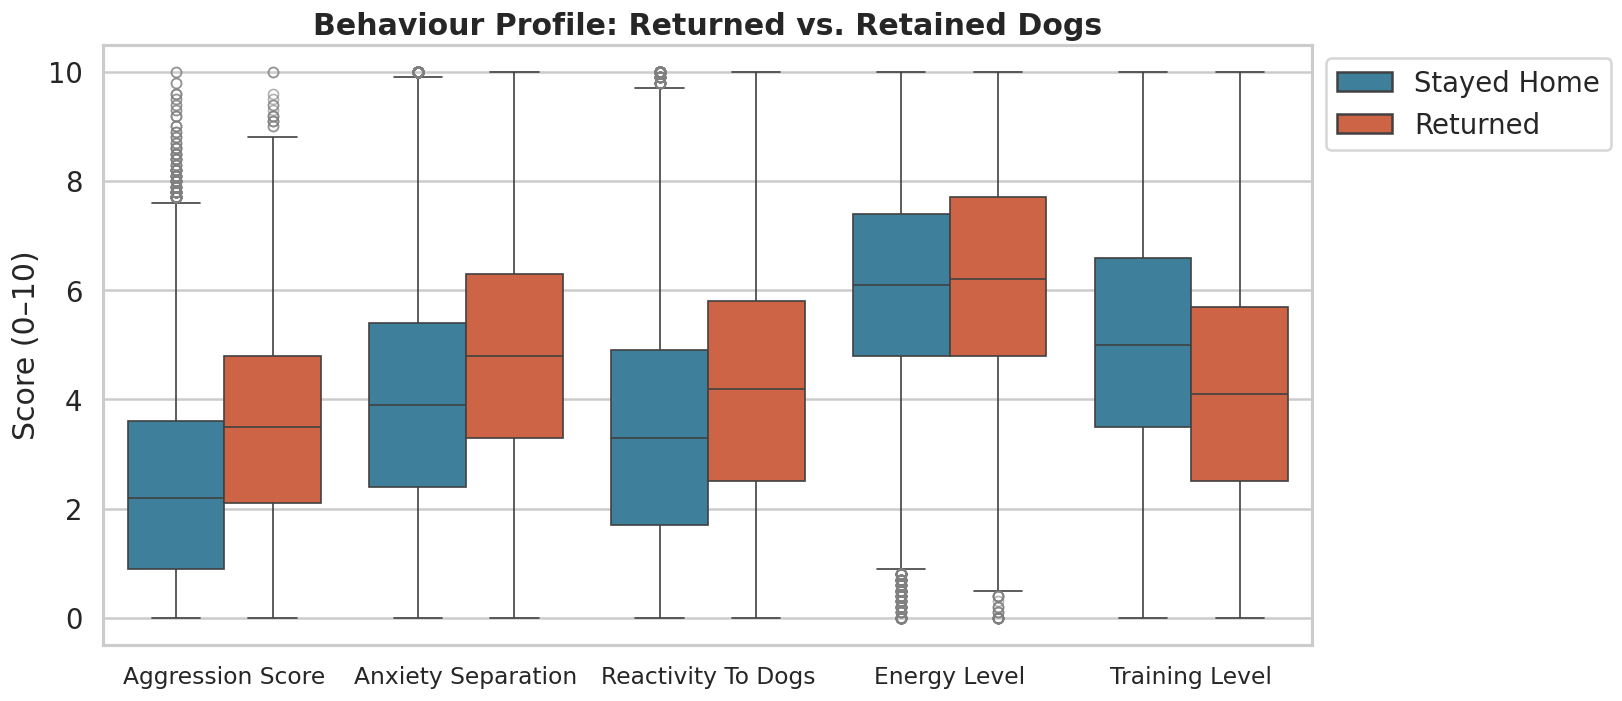

In [ ]:
behaviour = ["aggression_score", "anxiety_separation", "reactivity_to_dogs",
             "energy_level", "training_level"]
long = df.melt(id_vars="outcome", value_vars=behaviour,
               var_name="trait", value_name="score")
long["trait"] = long["trait"].str.replace("_", " ").str.title()

fig, ax = plt.subplots(figsize=(13, 6.5))
sns.boxplot(data=long, x="trait", y="score", hue="outcome",
            palette=[PALETTE["kept"], PALETTE["returned"]], ax=ax,
            fliersize=6,
            flierprops=dict(marker="o", markerfacecolor="none",
                             markeredgecolor="gray", alpha=.6))
ax.set_xlabel(""); ax.set_ylabel("Score (0–10)")
ax.set_title("Behaviour Profile: Returned vs. Retained Dogs")
ax.tick_params(axis="x", labelsize=14)

legend = ax.get_legend()
legend.set_title(None)
legend.set_bbox_to_anchor((1, 1))
show(fig, "03_behaviour_profile")

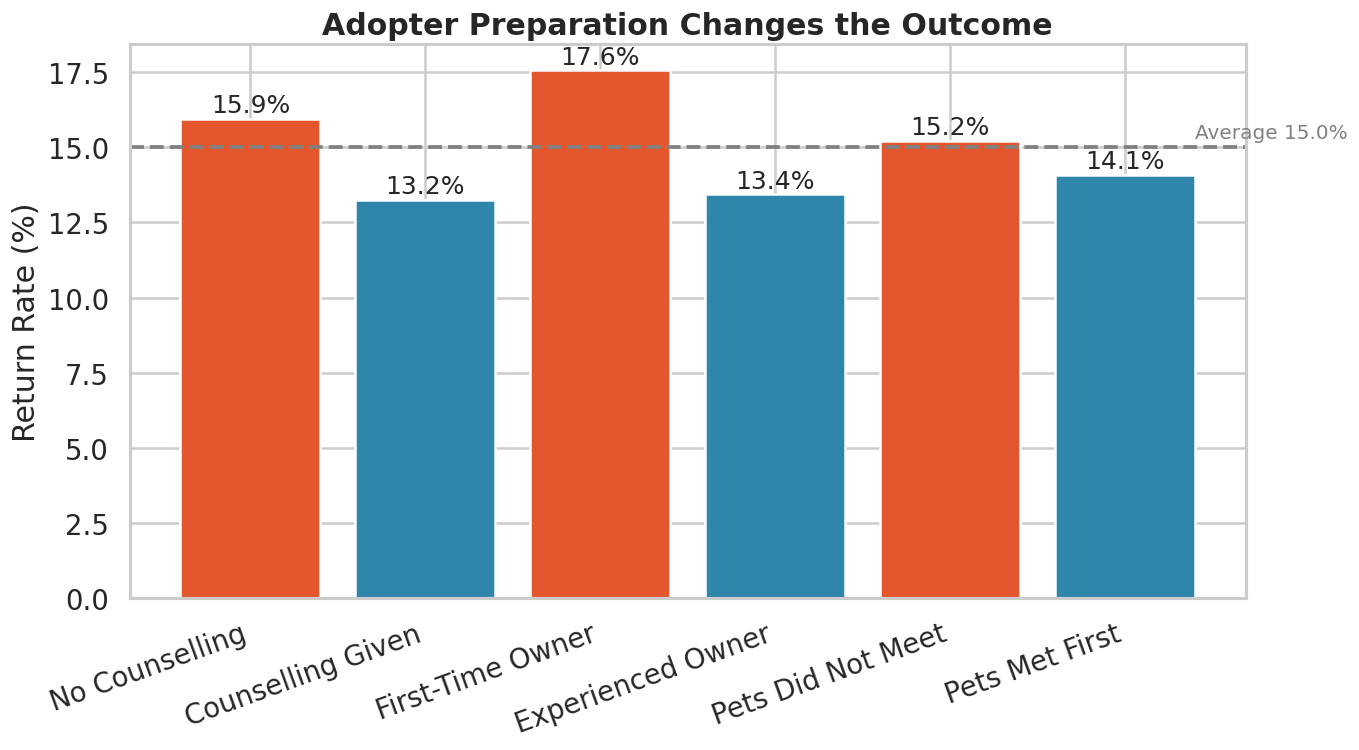

In [ ]:
prep = pd.DataFrame({
    "Factor": ["No Counselling", "Counselling Given",
               "First-Time Owner", "Experienced Owner",
               "Pets Did Not Meet", "Pets Met First"],
    "Return Rate": [
        df.loc[df.adoption_counseling == 0, "returned"].mean() * 100,
        df.loc[df.adoption_counseling == 1, "returned"].mean() * 100,
        df.loc[df.first_time_owner == 1, "returned"].mean() * 100,
        df.loc[df.first_time_owner == 0, "returned"].mean() * 100,
        df.loc[df.met_resident_pets == 0, "returned"].mean() * 100,
        df.loc[df.met_resident_pets == 1, "returned"].mean() * 100],
    "Group": ["Counselling"] * 2 + ["Experience"] * 2 + ["Meet & Greet"] * 2})

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.bar(prep["Factor"], prep["Return Rate"],
              color=["#E4572E", "#2E86AB"] * 3)
ax.bar_label(bars, fmt="%.1f%%", padding=1, fontsize=15)
ax.axhline(BASE, ls="--", c="grey")
ax.text(5.4, BASE + 0.3, f"Average {BASE:.1f}%", color="grey", fontsize=12)
ax.set_ylabel("Return Rate (%)"); plt.xticks(rotation=20, ha="right")
ax.set_title("Adopter Preparation Changes the Outcome")
show(fig, "04_adopter_preparation")

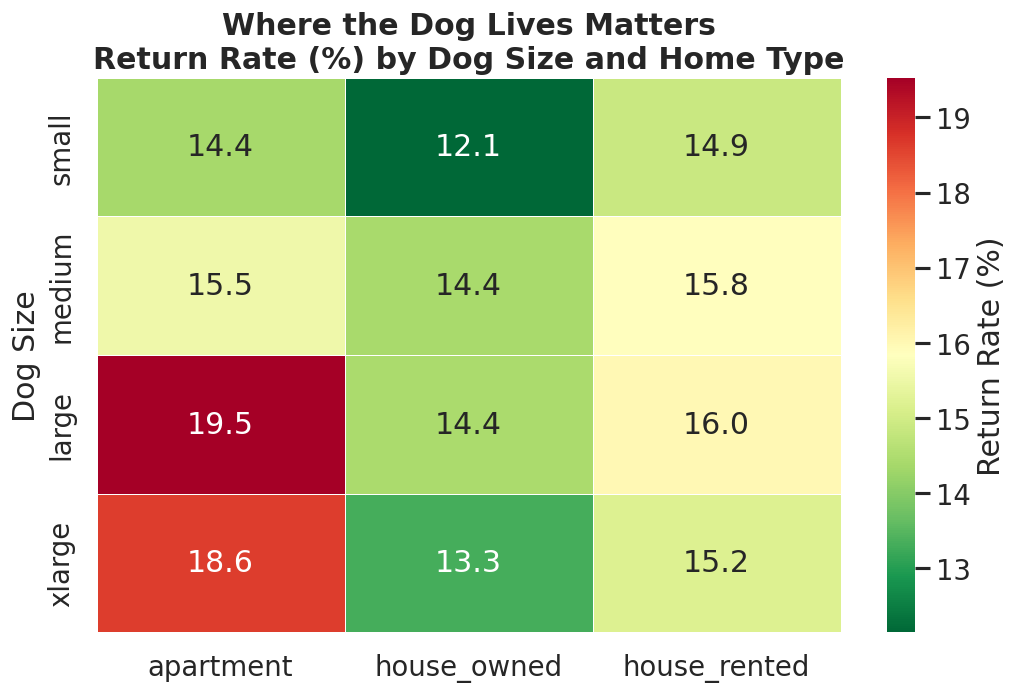

In [ ]:
size_map = {1: "small", 2: "medium", 3: "large", 4: "xlarge"}
df["size_label"] = df["size"].map(size_map)

pivot = (df.pivot_table(index="size_label", columns="home_type",
                        values="returned", aggfunc="mean") * 100)
pivot = pivot.reindex(["small", "medium", "large", "xlarge"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap='RdYlGn_r', ax=ax,
            cbar_kws={"label": "Return Rate (%)"}, linewidths=.5)
ax.set_xlabel(""); ax.set_ylabel("Dog Size")
ax.set_title("Where the Dog Lives Matters\n"
             "Return Rate (%) by Dog Size and Home Type")
show(fig, "06_size_vs_home")

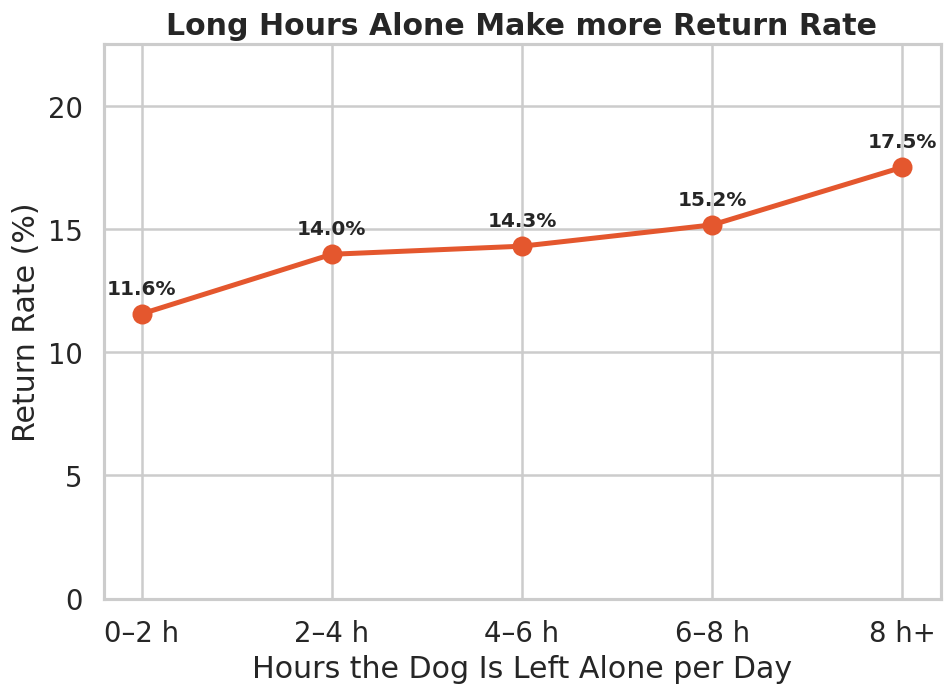

In [ ]:
df["alone_bin"] = pd.cut(df["hours_alone_per_day"], [-.1, 2, 4, 6, 8, 24],
                         labels=["0–2 h", "2–4 h", "4–6 h", "6–8 h", "8 h+"])
a = df.groupby("alone_bin", observed=True)["returned"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 6))
# เปลี่ยนเป็นกราฟเส้นเพื่อให้เห็น Trend ชัดเจนขึ้น
ax.plot(a.index.astype(str), a.values, marker="o", lw=3, ms=11, color=PALETTE["returned"])

# เพิ่มตัวเลขระบุเปอร์เซ็นต์
for x, y in zip(a.index.astype(str), a.values):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points",
                xytext=(0, 12), ha="center", fontsize=12, fontweight="bold")

ax.set_xlabel("Hours the Dog Is Left Alone per Day")
ax.set_ylabel("Return Rate (%)")
ax.set_ylim(0, max(a.values) + 5)
ax.set_title("Long Hours Alone Make more Return Rate")
show(fig, "07_hours_alone_trend")

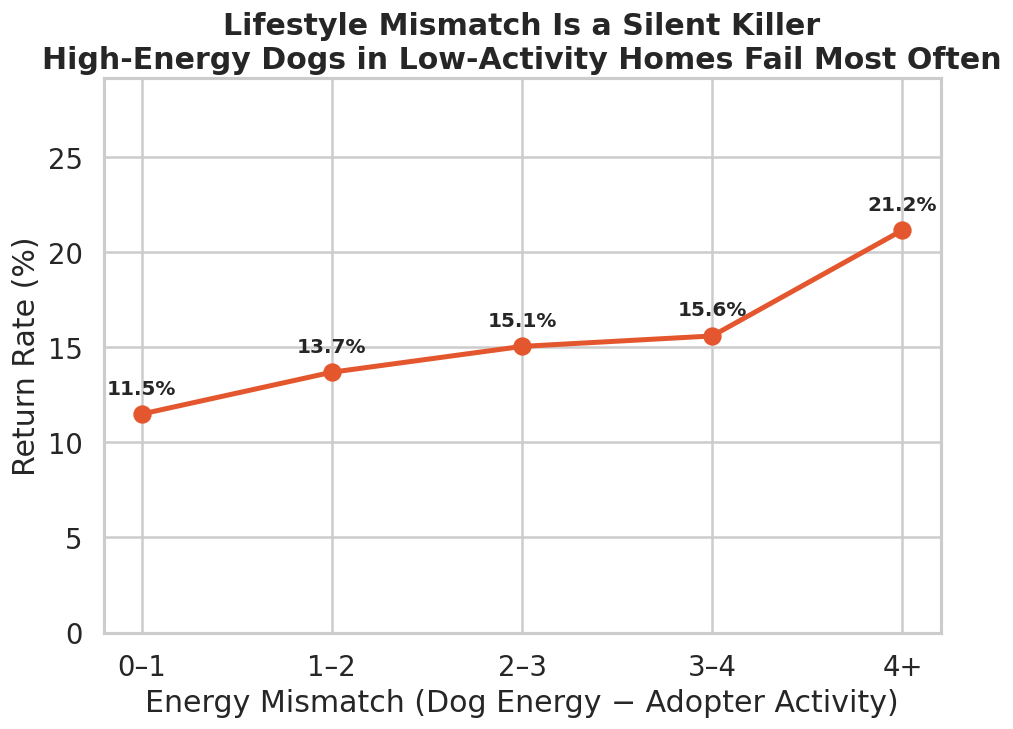

In [ ]:
df["mismatch_bin"] = pd.cut(df["energy_mismatch"], [-.1, 1, 2, 3, 4, 10],
                            labels=["0–1", "1–2", "2–3", "3–4", "4+"])
m = df.groupby("mismatch_bin", observed=True)["returned"].mean() * 100

fig, ax = plt.subplots(figsize=(9, 6))
# เปลี่ยนเป็นกราฟเส้น
ax.plot(m.index.astype(str), m.values, marker="o", lw=3, ms=10, color="#E4572E")

# เพิ่มตัวเลขระบุเปอร์เซ็นต์
for x, y in zip(m.index.astype(str), m.values):
    ax.annotate(f"{y:.1f}%", (x, y), textcoords="offset points",
                xytext=(0, 12), ha="center", fontsize=12, fontweight="bold")

ax.set_xlabel("Energy Mismatch (Dog Energy − Adopter Activity)")
ax.set_ylabel("Return Rate (%)")
ax.set_ylim(0, max(m.values) + 8)
ax.set_title("Lifestyle Mismatch Is a Silent Killer\n"
             "High-Energy Dogs in Low-Activity Homes Fail Most Often")
show(fig, "08_energy_mismatch_trend")

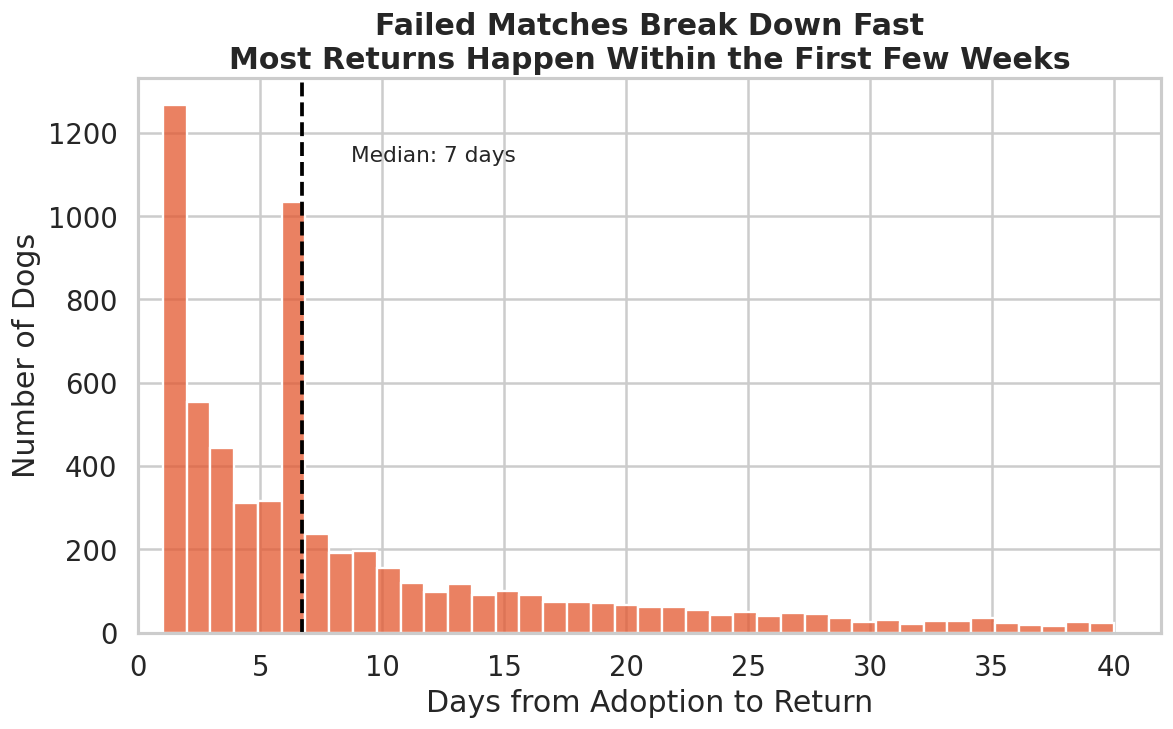

In [ ]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.histplot(df.loc[df.returned == 1, "days_to_return"], bins=40,
             color=PALETTE["returned"], ax=ax, edgecolor="white")
med = df["days_to_return"].median()
ax.axvline(med, ls="--", c="black")
ax.text(med + 2, ax.get_ylim()[1] * .85, f"Median: {med:.0f} days", fontsize=13)
ax.set_xlabel("Days from Adoption to Return"); ax.set_ylabel("Number of Dogs")
ax.set_title("Failed Matches Break Down Fast\n"
             "Most Returns Happen Within the First Few Weeks")
pltxlim = ax.get_xlim()
plt.xlim(0, None)
show(fig, "10_days_to_return")

/tmp/ipykernel_3429/2247676058.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, y="return_reason", x="days_to_return", order=order,


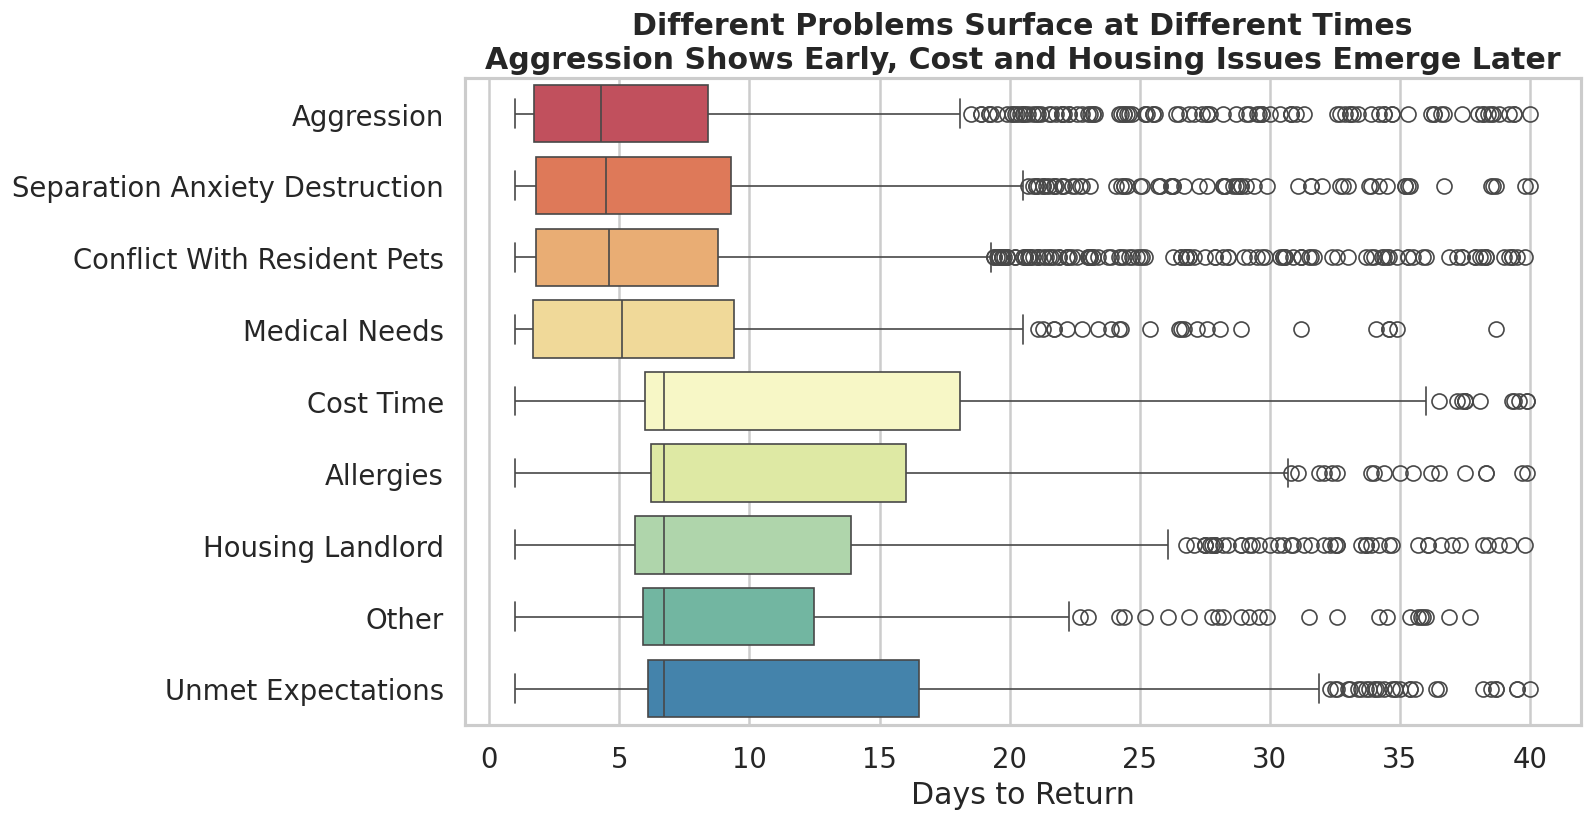

In [ ]:
sub = df[df.returned == 1].copy()
sub["return_reason"] = sub["return_reason"].str.replace("_", " ").str.title()
order = sub.groupby("return_reason")["days_to_return"].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=sub, y="return_reason", x="days_to_return", order=order,
            palette="Spectral", ax=ax)
ax.set_xlabel("Days to Return"); ax.set_ylabel("")
ax.set_title("Different Problems Surface at Different Times\n"
             "Aggression Shows Early, Cost and Housing Issues Emerge Later")
show(fig, "11_reason_vs_timing")

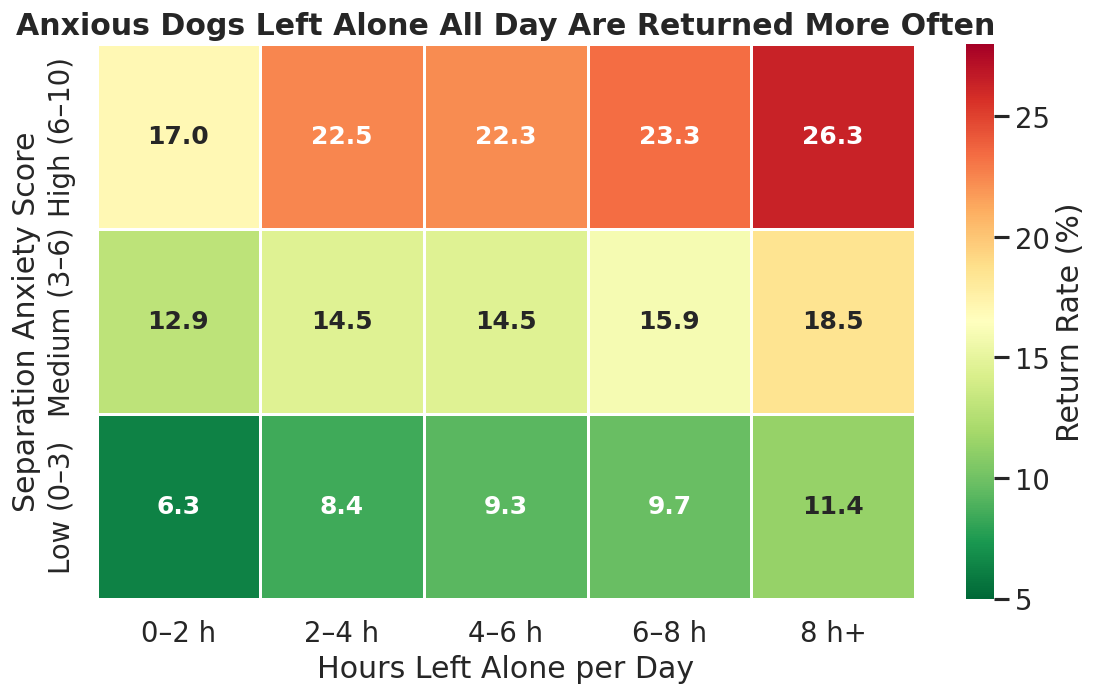

In [ ]:
# ============================================================
# 13. Separation Anxiety × Hours Alone — The Deadly Combination
# ============================================================
from scipy import stats

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"
plt.rcParams["axes.titleweight"] = "bold"

BASE = df["returned"].mean() * 100

# --- binning ---
alone_bins  = [-.1, 2, 4, 6, 8, 24]
alone_lbl   = ["0–2 h", "2–4 h", "4–6 h", "6–8 h", "8 h+"]
anx_bins    = [-.1, 3, 6, 10]
anx_lbl     = ["Low (0–3)", "Medium (3–6)", "High (6–10)"]

df["alone_bin"] = pd.cut(df.hours_alone_per_day, alone_bins, labels=alone_lbl)
df["anx_bin"]   = pd.cut(df.anxiety_separation, anx_bins,   labels=anx_lbl)

pivot = (df.pivot_table(index="anx_bin", columns="alone_bin",
                        values="returned", aggfunc="mean", observed=True) * 100
        ).reindex(anx_lbl[::-1])

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=.8,
            ax=ax, cbar_kws={"label": "Return Rate (%)"},
            annot_kws={"size": 15, "weight": "bold"}, vmin=5, vmax=28)
ax.set_xlabel("Hours Left Alone per Day"); ax.set_ylabel("Separation Anxiety Score")
ax.set_title("Anxious Dogs Left Alone All Day Are Returned More Often")
plt.savefig("13a_anxiety_x_alone_heatmap.png"); plt.show()

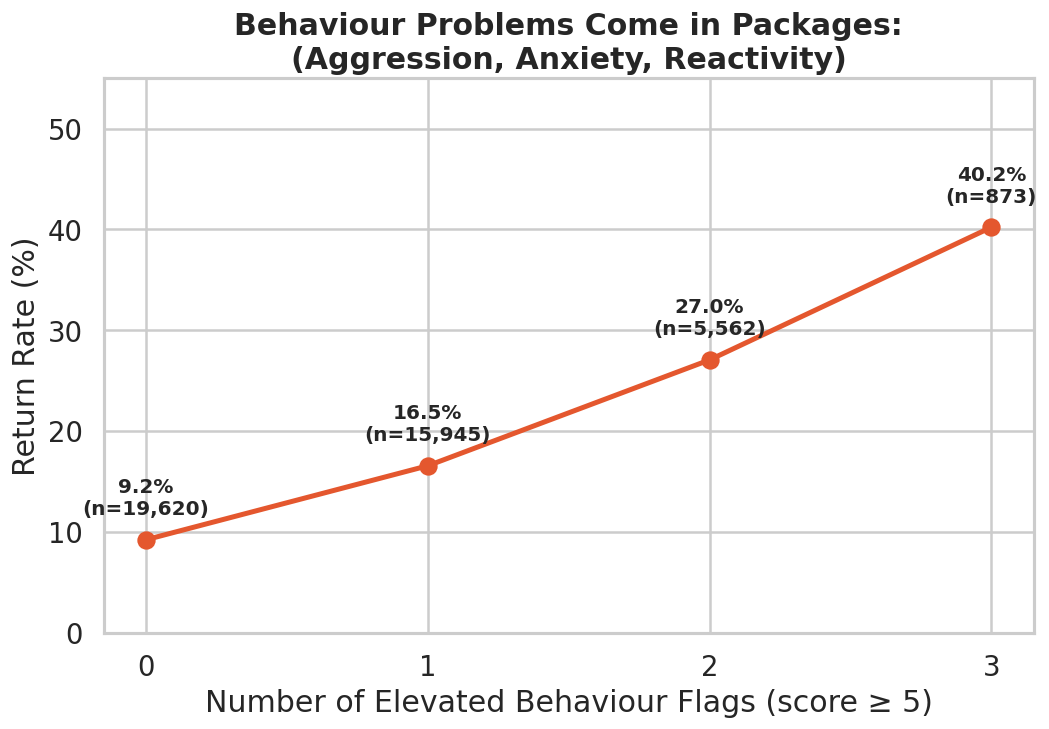

In [ ]:
df["n_flags"] = ((df.aggression_score >= 5).astype(int)
               + (df.anxiety_separation >= 5).astype(int)
               + (df.reactivity_to_dogs >= 5).astype(int))
b = df.groupby("n_flags")["returned"].agg(["mean", "size"])
b["mean"] *= 100

fig, ax = plt.subplots(figsize=(10, 6))
# เปลี่ยนเป็นกราฟเส้นเพื่อแสดง Trend
ax.plot(b.index.astype(str), b["mean"], marker='o', lw=3, ms=10, color="#E4572E")

# เพิ่มตัวเลขระบุเปอร์เซ็นต์และจำนวนตัวอย่าง (n)
for x, (rate, n) in zip(b.index.astype(str), b.values):
    ax.annotate(f"{rate:.1f}%\n(n={int(n):,})", (x, rate), textcoords="offset points",
                xytext=(0, 15), ha="center", fontsize=12, fontweight="bold")

ax.set_xlabel("Number of Elevated Behaviour Flags (score ≥ 5)")
ax.set_ylabel("Return Rate (%)")
ax.set_ylim(0, 55)
ax.set_title("Behaviour Problems Come in Packages:\n(Aggression, Anxiety, Reactivity)")
plt.savefig("14_behaviour_burden_trend.png")
plt.show()

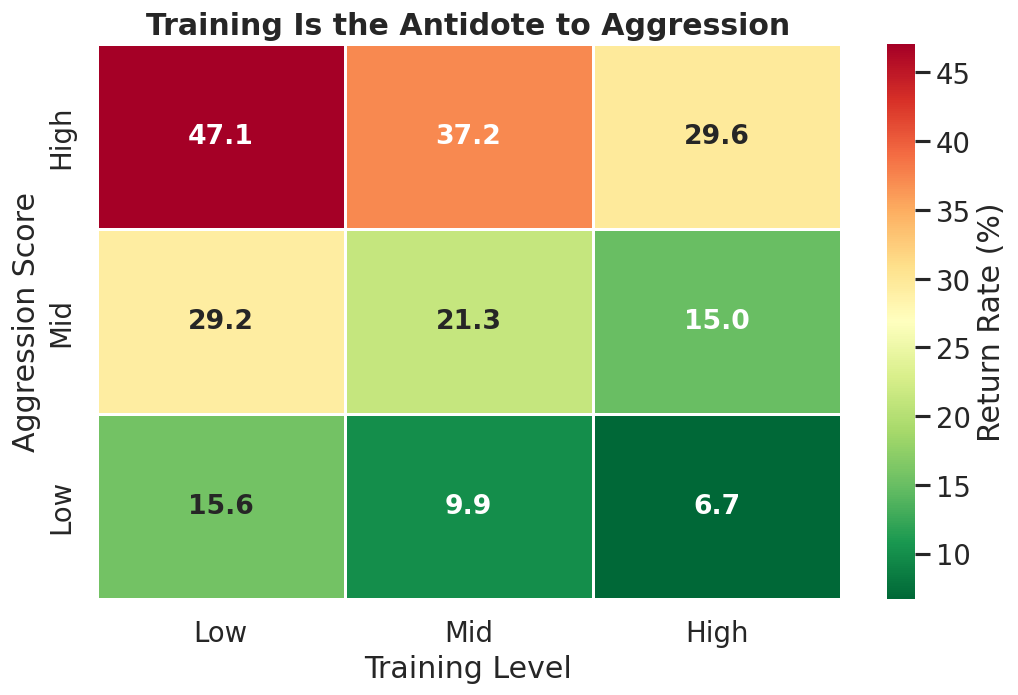

In [ ]:
df["tr_bin"]  = pd.cut(df.training_level,   [-.1,3,6,10], labels=["Low","Mid","High"])
df["agg_bin"] = pd.cut(df.aggression_score, [-.1,3,6,10], labels=["Low","Mid","High"])
p = (df.pivot_table(index="agg_bin", columns="tr_bin",
                    values="returned", aggfunc="mean", observed=True)*100
    ).reindex(["High","Mid","Low"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(p, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=.8, ax=ax,
            annot_kws={"size":16,"weight":"bold"}, cbar_kws={"label":"Return Rate (%)"})
ax.set_xlabel("Training Level"); ax.set_ylabel("Aggression Score")
ax.set_title("Training Is the Antidote to Aggression")
plt.savefig("15_training_buffer.png"); plt.show()

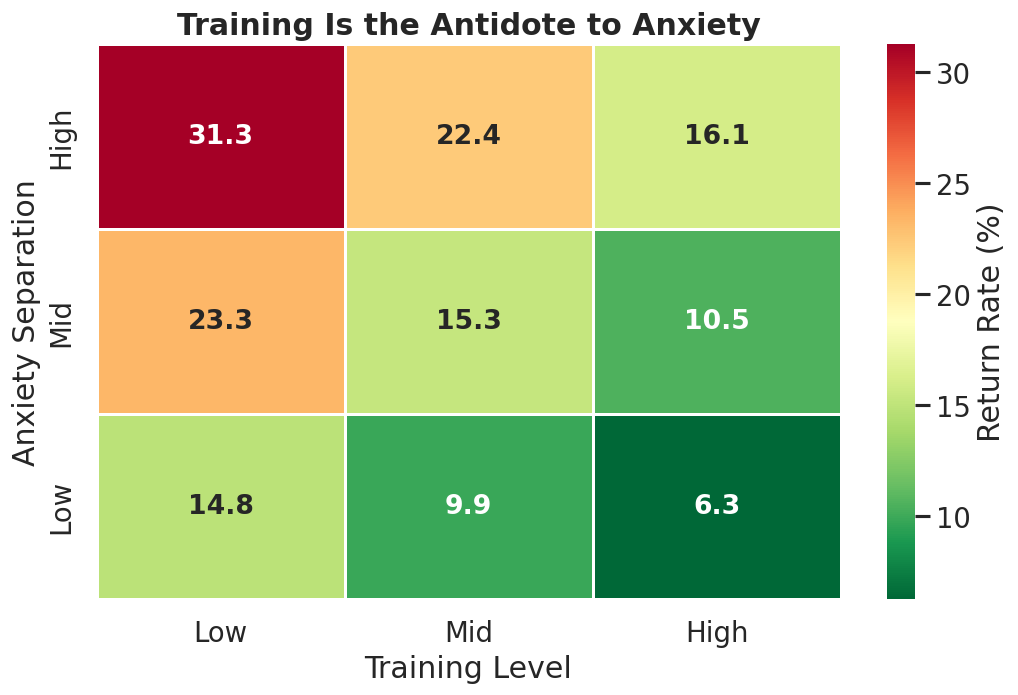

In [ ]:
df["tr_bin"]  = pd.cut(df.training_level,   [-.1,3,6,10], labels=["Low","Mid","High"])
df["agg_bin"] = pd.cut(df.anxiety_separation, [-.1,3,6,10], labels=["Low","Mid","High"])
p = (df.pivot_table(index="agg_bin", columns="tr_bin",
                    values="returned", aggfunc="mean", observed=True)*100
    ).reindex(["High","Mid","Low"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(p, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=.8, ax=ax,
            annot_kws={"size":16,"weight":"bold"}, cbar_kws={"label":"Return Rate (%)"})
ax.set_xlabel("Training Level"); ax.set_ylabel("Anxiety Separation")
ax.set_title("Training Is the Antidote to Anxiety")
plt.savefig("15_training_buffer.png"); plt.show()

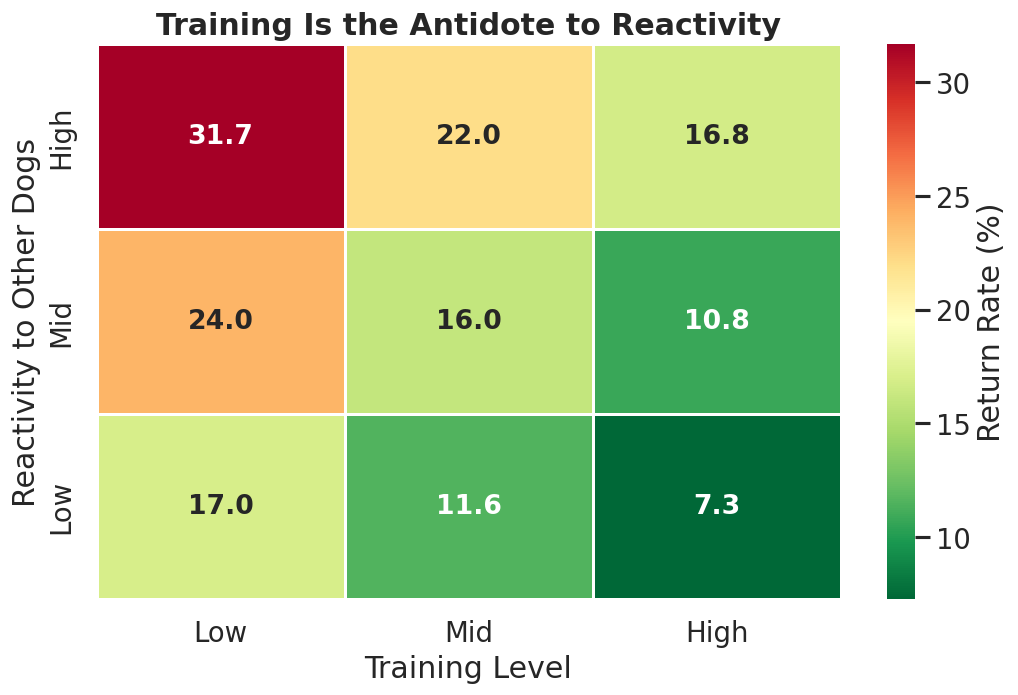

In [ ]:
df["tr_bin"]  = pd.cut(df.training_level,   [-.1,3,6,10], labels=["Low","Mid","High"])
df["agg_bin"] = pd.cut(df.reactivity_to_dogs, [-.1,3,6,10], labels=["Low","Mid","High"])
p = (df.pivot_table(index="agg_bin", columns="tr_bin",
                    values="returned", aggfunc="mean", observed=True)*100
    ).reindex(["High","Mid","Low"])

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(p, annot=True, fmt=".1f", cmap="RdYlGn_r", linewidths=.8, ax=ax,
            annot_kws={"size":16,"weight":"bold"}, cbar_kws={"label":"Return Rate (%)"})
ax.set_xlabel("Training Level"); ax.set_ylabel("Reactivity to Other Dogs")
ax.set_title("Training Is the Antidote to Reactivity")
plt.savefig("15_training_buffer.png"); plt.show()

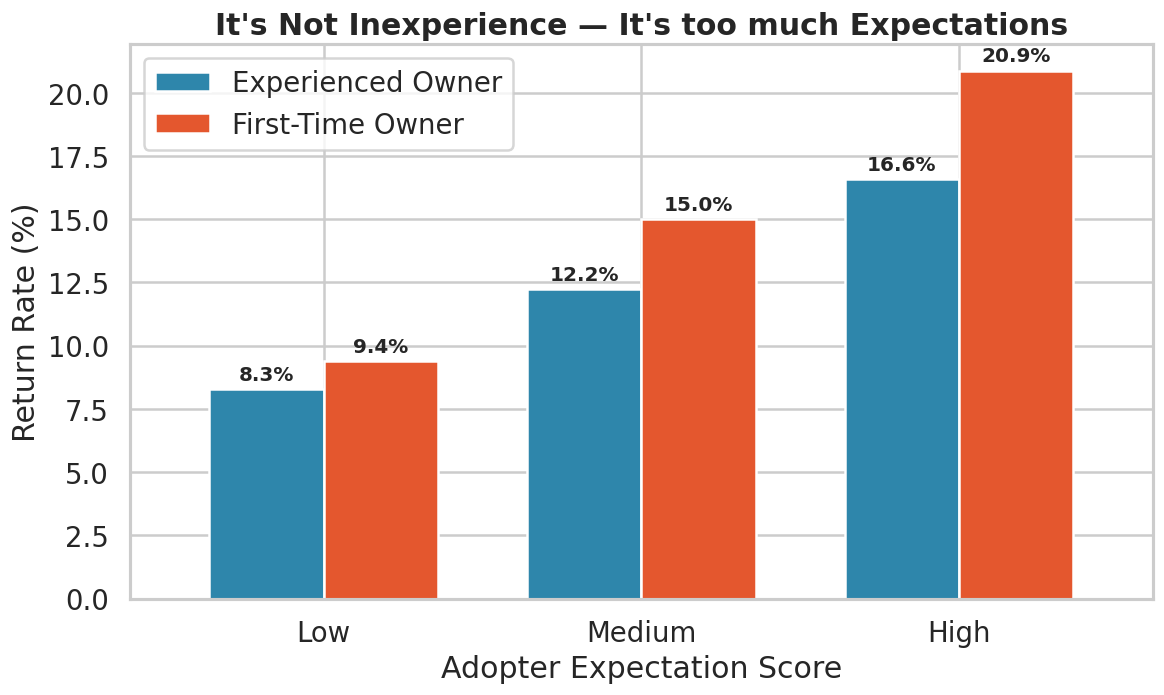

In [ ]:
df["exp_bin"] = pd.cut(df.expectation_score, [-.1,4,7,10],
                       labels=["Low","Medium","High"])
m = (df.groupby(["exp_bin","first_time_owner"], observed=True)["returned"]
       .mean().mul(100).unstack())
m.columns = ["Experienced Owner", "First-Time Owner"]

fig, ax = plt.subplots(figsize=(11, 6))
m.plot(kind="bar", ax=ax, color=[PALETTE["kept"], PALETTE["returned"]],
       rot=0, width=.72, edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=3, fontsize=12, fontweight="bold")
ax.set_xlabel("Adopter Expectation Score"); ax.set_ylabel("Return Rate (%)")
ax.legend(title="")
ax.set_title("It's Not Inexperience — It's too much Expectations")
plt.savefig("16_expectation_mediation.png"); plt.show()

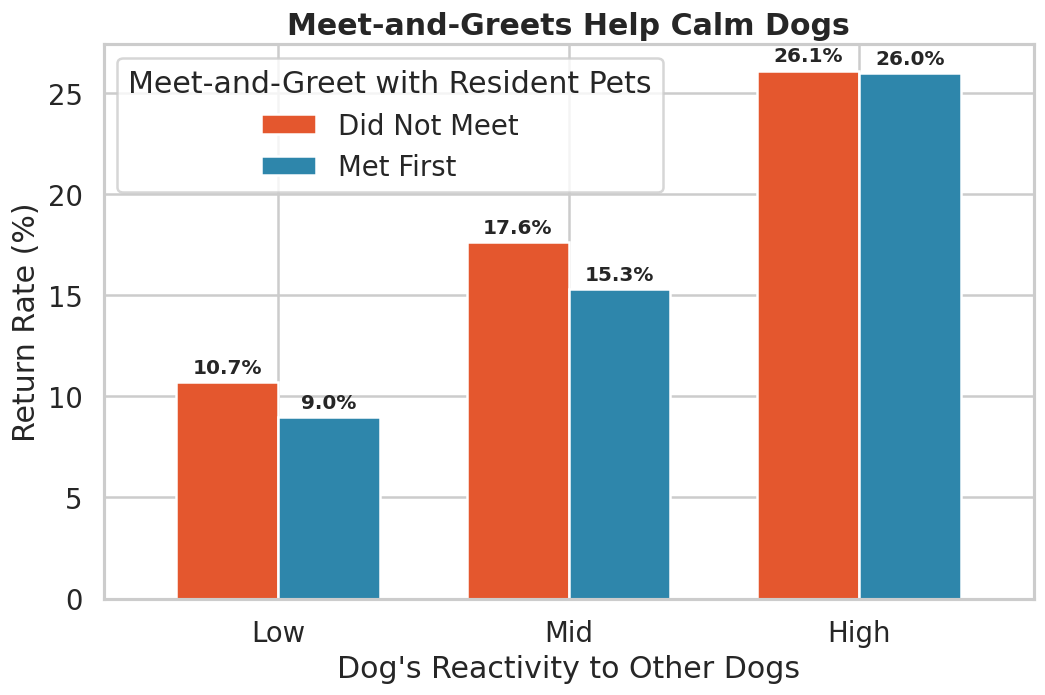

In [ ]:
df["rx_bin"] = pd.cut(df.reactivity_to_dogs, [-.1,3,6,10], labels=["Low","Mid","High"])
w = df[df.household_has_pets == 1]
g = (w.groupby(["rx_bin","met_resident_pets"], observed=True)["returned"]
       .mean().mul(100).unstack())
g.columns = ["Did Not Meet", "Met First"]

fig, ax = plt.subplots(figsize=(10, 6))
g.plot(kind="bar", ax=ax, rot=0, width=.7,
       color=[PALETTE["returned"], PALETTE["kept"]], edgecolor="white")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=3, fontsize=12, fontweight="bold")
ax.set_xlabel("Dog's Reactivity to Other Dogs"); ax.set_ylabel("Return Rate (%)")
ax.legend(title="Meet-and-Greet with Resident Pets")
ax.set_title("Meet-and-Greets Help Calm Dogs")
plt.savefig("18_meet_greet_limits.png"); plt.show()

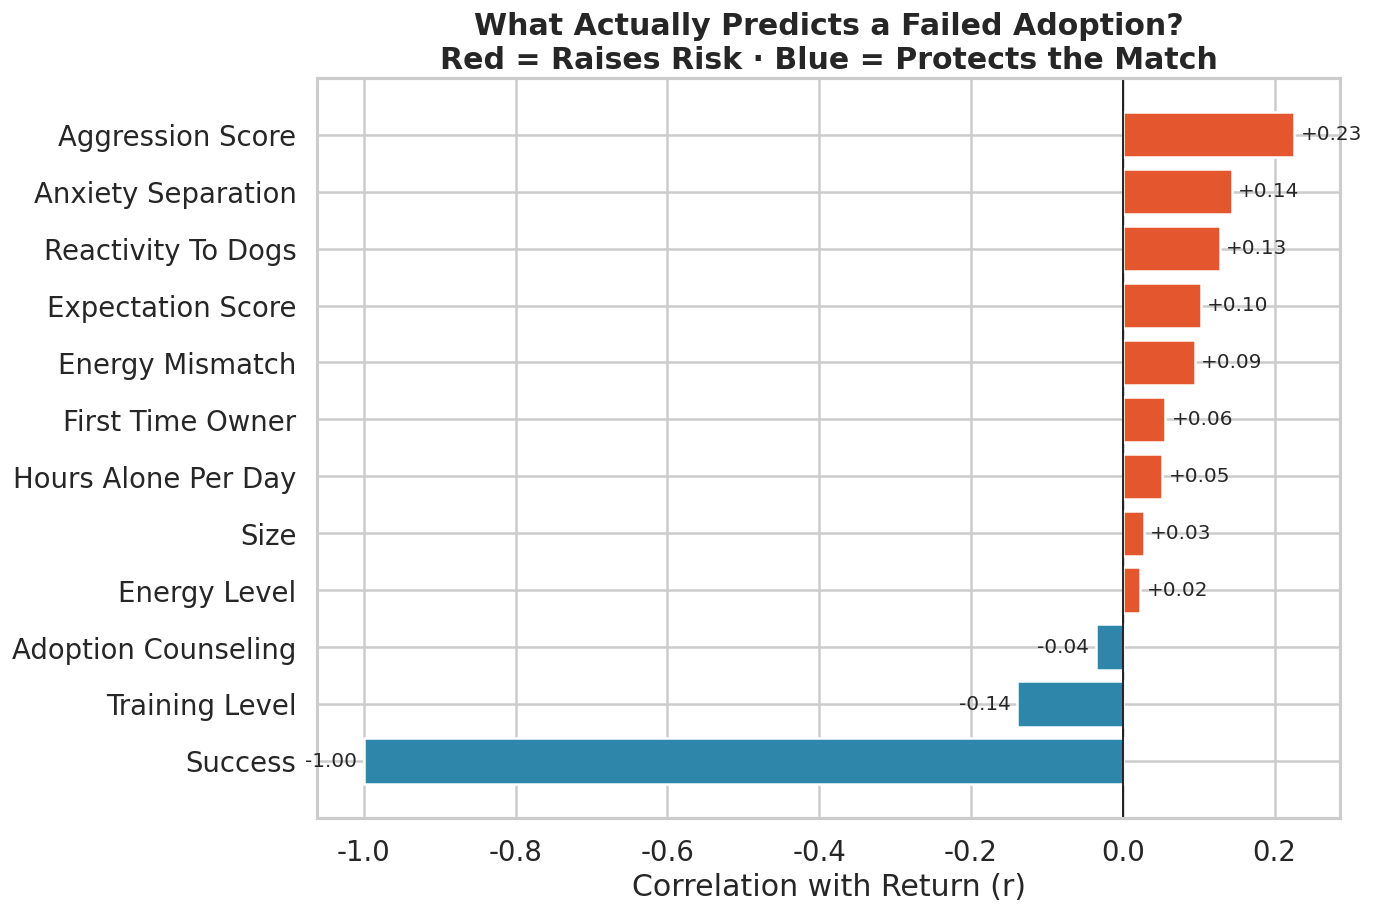

In [ ]:
num = df.select_dtypes("number").drop(columns=["returned","days_to_return"], errors="ignore")
corr = num.corrwith(df["returned"]).drop(labels=[c for c in
        ["n_flags"] if c in num.columns], errors="ignore")
corr = corr[corr.abs() > .02].sort_values()

fig, ax = plt.subplots(figsize=(11, 8))
colors = [PALETTE["returned"] if v > 0 else PALETTE["kept"] for v in corr]
bars = ax.barh([i.replace("_"," ").title() for i in corr.index], corr.values, color=colors)
ax.bar_label(bars, fmt="%+.2f", padding=4, fontsize=12)
ax.axvline(0, c="black", lw=1)
ax.set_xlabel("Correlation with Return (r)")
ax.set_title("What Actually Predicts a Failed Adoption?\n"
             "Red = Raises Risk · Blue = Protects the Match")
plt.savefig("19_correlation_tornado.png"); plt.show()

In [ ]:
df['return_reason'].value_counts()

,count
return_reason,
kept,35703
conflict_with_resident_pets,1387
aggression,1352
separation_anxiety_destruction,975
unmet_expectations,750
housing_landlord,535
cost_time,512
medical_needs,316
allergies,238


                              count       mean  median  mode
mode                                                        
Behavioural / Medical Crisis   4268   7.343369     4.8   1.0
Practical / Expectation Gap    2029  11.320749     6.7   6.7


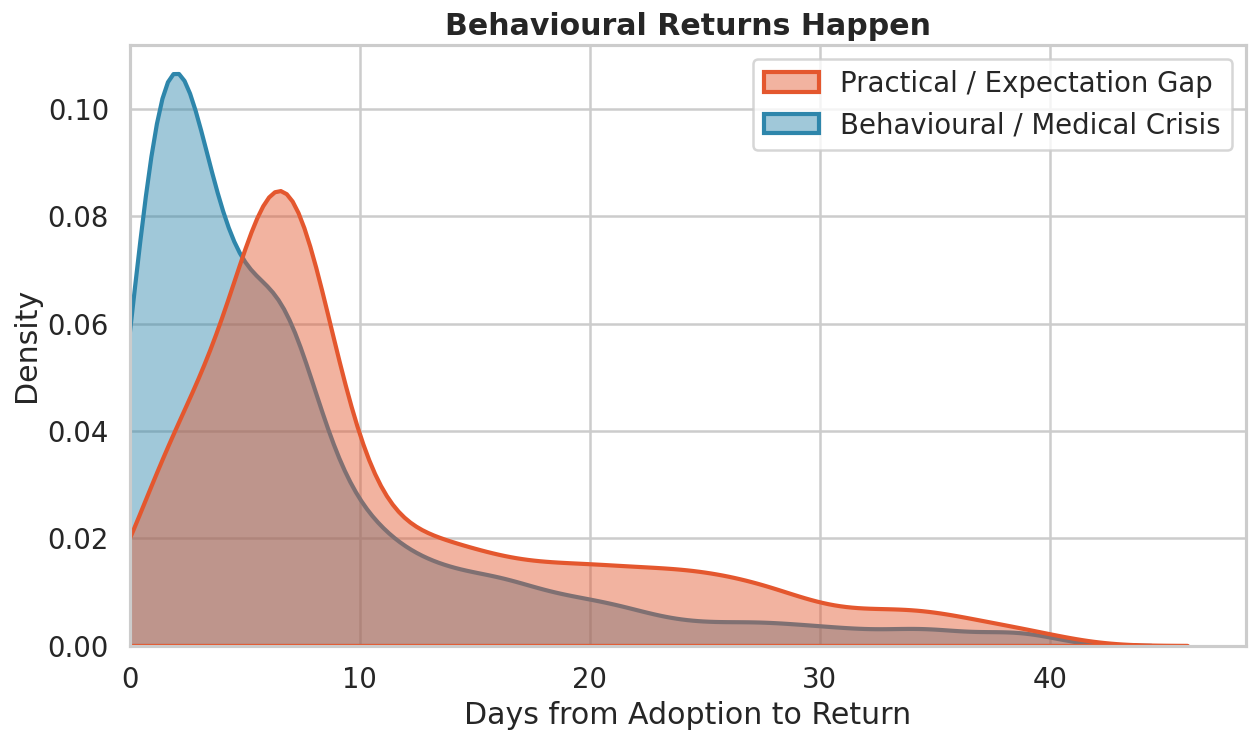

In [ ]:
sub = df[df.returned == 1].copy()
FAST = ["aggression","separation_anxiety_destruction",
        "conflict_with_resident_pets","medical_needs", "allergies"]
sub["mode"] = np.where(sub.return_reason.isin(FAST),
                       "Behavioural / Medical Crisis", "Practical / Expectation Gap")

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.kdeplot(data=sub, x="days_to_return", hue="mode", fill=True, alpha=.45,
            common_norm=False, lw=2.5, ax=ax,
            palette=[PALETTE["returned"], PALETTE["kept"]])
legend = ax.get_legend()
legend.set_title(None)

for mode, c in zip(sub["mode"].unique(), [PALETTE["returned"], PALETTE["kept"]]):
    mu = sub.loc[sub["mode"] == mode, "days_to_return"].mean()
ax.set_xlabel("Days from Adoption to Return"); ax.set_ylabel("Density")
ax.set_title(
"Behavioural Returns Happen")
plt.xlim(0, None)
print(sub.groupby("mode")["days_to_return"].agg(["count", "mean", "median",('mode', lambda x: x.mode().iloc[0] if not x.empty else np.nan)]))

plt.savefig("17_two_failure_modes.png"); plt.show()

# Machine Learning: Return-Risk Model (v2)

Goal: estimate the probability that an adopted dog is returned, using only information that is available at, or before, the adoption decision.

> **Leakage guard:** `adoption_id`, `return_reason`, `days_to_return`, `success`, and `outcome` are excluded. They are identifiers or are known only after the outcome.

**What changed from v1**

- Kept only the engineered interactions that survived a likelihood-ratio screen: reactivity × resident pets, and whether the adopter met those pets.
- Added a change of slope for age and weight (risk falls for puppies/small dogs and then flattens) instead of forcing one straight line.
- Removed `class_weight='balanced'`. The unweighted likelihood keeps predicted probabilities on the real 15% scale, so the review threshold is an actual risk level rather than an inflated score.
- Selected the model with 5-fold cross-validation on the training half only, chose the F2 threshold from out-of-fold predictions, and added bootstrap confidence intervals, calibration, review-capacity and risk-tier tables.

**How to read it:** PR-AUC is the primary metric because returned dogs are the 15% minority. The F2 threshold is deliberately recall-heavy (it reviews about half the dogs); the capacity table shows the precision/recall trade-off for smaller review budgets.

**Why a linear model?** The engineered logistic model beats the non-linear benchmark, which indicates the signal in this dataset is mostly additive. More model complexity is not the path to better performance; new pre-adoption information would be.


,model,cv_pr_auc,cv_pr_auc_sd,test_pr_auc,test_roc_auc,test_brier
0,"Logistic Regression (engineered, selected)",0.371,0.015,0.381,0.762,0.111
1,Logistic Regression (raw features),0.368,0.015,0.375,0.759,0.111
2,Histogram Gradient Boosting (engineered),0.356,0.017,0.355,0.748,0.113


Rows: 42,000; return rate: 15.0%; test rows: 8,400
Chosen model (highest CV PR-AUC): Logistic Regression (engineered, selected)
PR-AUC gain over raw baseline: CV +0.003, test +0.007
CV PR-AUC 0.371 +/- 0.015
Test PR-AUC 0.381 (95% bootstrap CI 0.353-0.410)
Test ROC-AUC 0.762 (95% CI 0.749-0.776)
Brier score 0.111  (lower is better; prevalence 0.150)
F2 review threshold from out-of-fold predictions: 0.107  (flags 51.4% of test dogs)
              precision    recall  f1-score   support

 Stayed home       0.95      0.54      0.69      7141
    Returned       0.24      0.82      0.37      1259

    accuracy                           0.58      8400
   macro avg       0.59      0.68      0.53      8400
weighted avg       0.84      0.58      0.64      8400



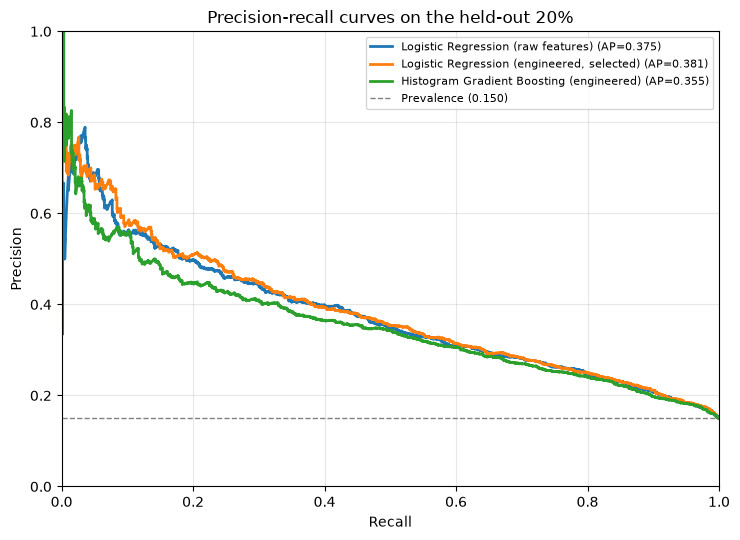

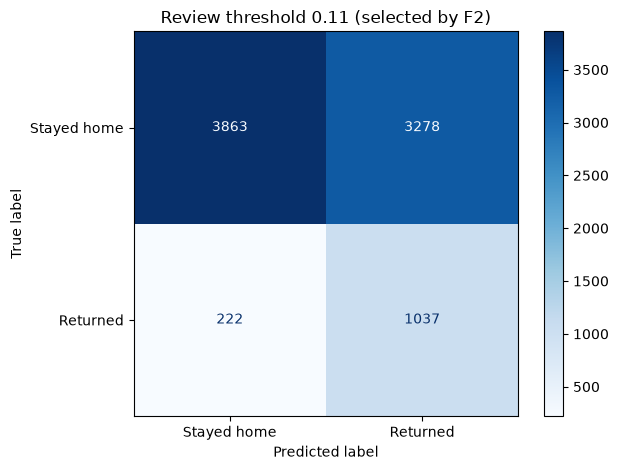

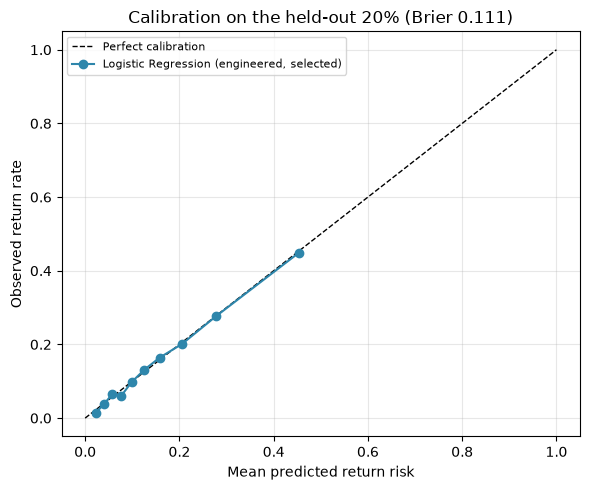

,review_budget,dogs_flagged,precision,lift,recall
0,top 10%,840,0.449,3.0x,0.299
1,top 20%,1680,0.362,2.4x,0.484
2,top 30%,2520,0.309,2.1x,0.618
3,top 40%,3360,0.273,1.8x,0.728
4,top 50%,4200,0.244,1.6x,0.815


Top-10% review budget: 44.9% precision, 29.9% recall, 3.0x lift


,risk_tier,dogs,returns,return_rate
0,<5%,1734,49,2.8%
1,5-10%,2111,147,7.0%
2,10-15%,1446,184,12.7%
3,15-25%,1599,310,19.4%
4,25%+,1510,569,37.7%


,feature,importance_mean,importance_std
9,aggression_score,0.0665,0.0066
29,pets_reactivity,0.0356,0.0029
25,expectation_score,0.0341,0.0035
13,training_level,0.0235,0.0063
28,behavior_risk_mean,0.0228,0.0046
26,energy_mismatch,0.0214,0.0055
22,visits_before_adoption,0.0126,0.0023
10,anxiety_separation,0.0109,0.0031
15,first_time_owner,0.0085,0.0014
27,size_home_mismatch,0.0082,0.0019


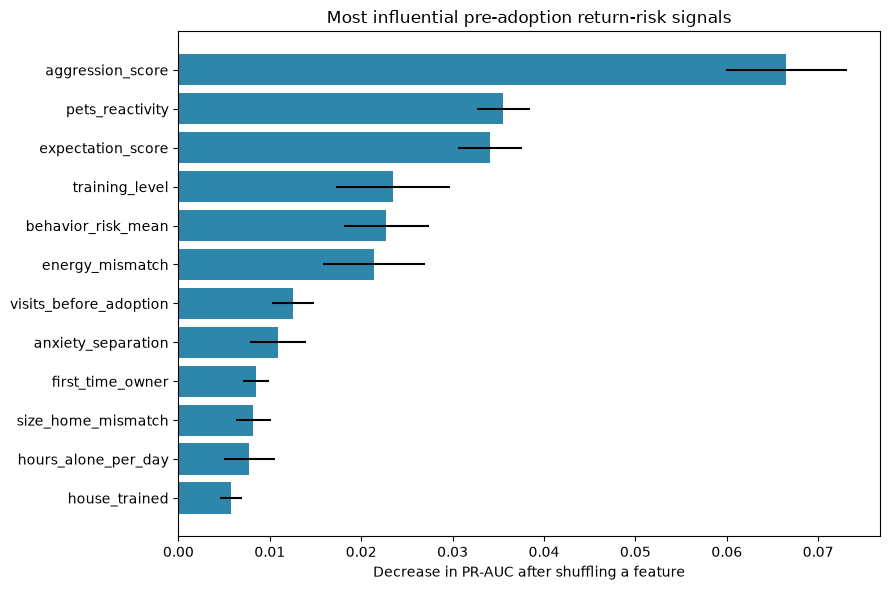

In [1]:
# Feature engineering + leakage-safe return-risk modelling (v2)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             precision_recall_curve, classification_report, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# --- 1. Load the raw data and build pre-adoption features ---------------------------------
RANDOM_STATE, TARGET = 42, 'returned'
candidates = [Path('../dog_adoption/dog_adoption_master.csv'), Path('dog_adoption/dog_adoption_master.csv'), Path('/content/dog_adoption_master.csv')]
data_path = next((p for p in candidates if p.exists()), None)
if data_path is None:
    raise FileNotFoundError('Update candidates with the location of dog_adoption_master.csv')
raw_ml = pd.read_csv(data_path)

# Outcome-only fields are never used as predictors.
LEAKAGE = ['adoption_id', 'return_reason', 'days_to_return', 'success', 'outcome']
X_base = raw_ml.drop(columns=LEAKAGE + [TARGET], errors='ignore').copy()
y = raw_ml[TARGET].astype(int)

def engineer_features(X):
    """Pre-adoption features only. Interactions are the ones that survived a likelihood-ratio screen."""
    X = X.copy()
    X['behavior_risk_mean'] = X[['aggression_score', 'anxiety_separation', 'reactivity_to_dogs']].mean(axis=1)
    # Reactivity is only a material risk when the adopter already has pets, and meeting those pets lowers it.
    X['pets_reactivity'] = X['household_has_pets'] * X['reactivity_to_dogs']
    X['pets_reactivity_unmet'] = X['pets_reactivity'] * (1 - X['met_resident_pets'])
    X['risk_flag_count'] = ((X['aggression_score'] >= 5).astype(int) + (X['anxiety_separation'] >= 5).astype(int) +
                            (X['reactivity_to_dogs'] >= 5).astype(int) + (X['hours_alone_per_day'] >= 8).astype(int))
    # Risk is lower for young puppies and small dogs and then flattens, so allow one change of slope.
    X['age_2plus'] = (X['age_years'] >= 2).astype(int)
    X['weight_10plus'] = (X['weight_kg'] >= 10).astype(int)
    return X

X_engineered = engineer_features(X_base)
X_train_b, X_test_b, y_train, y_test = train_test_split(X_base, y, test_size=.20, stratify=y, random_state=RANDOM_STATE)
X_train_e, X_test_e, _, _ = train_test_split(X_engineered, y, test_size=.20, stratify=y, random_state=RANDOM_STATE)

def make_preprocessor(X):
    cat_cols = X.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
    num_cols = [c for c in X.columns if c not in cat_cols]
    return ColumnTransformer([
        ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
        ('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cat_cols),
    ])

def linear_model(C=0.1):
    # Unweighted likelihood keeps predicted probabilities close to the real return rate.
    return LogisticRegression(max_iter=4_000, C=C, random_state=RANDOM_STATE)

# --- 2. Candidate models: raw baseline, engineered linear model, non-linear benchmark ----
models = {
    'Logistic Regression (raw features)': dict(
        pipeline=Pipeline([('prep', make_preprocessor(X_base)), ('model', linear_model())]),
        X_train=X_train_b, X_test=X_test_b),
    'Logistic Regression (engineered, selected)': dict(
        pipeline=Pipeline([('prep', make_preprocessor(X_engineered)), ('model', linear_model())]),
        X_train=X_train_e, X_test=X_test_e),
    'Histogram Gradient Boosting (engineered)': dict(
        pipeline=Pipeline([('prep', make_preprocessor(X_engineered)), ('model', HistGradientBoostingClassifier(
            max_iter=300, learning_rate=.06, max_leaf_nodes=15, min_samples_leaf=40,
            l2_regularization=1., random_state=RANDOM_STATE))]),
        X_train=X_train_e, X_test=X_test_e),
}

# --- 3. Model selection: 5-fold CV on the training half only; the test half is touched once.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fitted, comparison = {}, []
for name, spec in models.items():
    scores = cross_validate(spec['pipeline'], spec['X_train'], y_train, cv=cv,
                            scoring={'pr': 'average_precision', 'roc': 'roc_auc'}, n_jobs=5)
    spec['pipeline'].fit(spec['X_train'], y_train)
    probability = spec['pipeline'].predict_proba(spec['X_test'])[:, 1]
    fitted[name] = dict(spec=spec, probability=probability)
    comparison.append({'model': name, 'cv_pr_auc': scores['test_pr'].mean(), 'cv_pr_auc_sd': scores['test_pr'].std(),
                       'test_pr_auc': average_precision_score(y_test, probability),
                       'test_roc_auc': roc_auc_score(y_test, probability),
                       'test_brier': brier_score_loss(y_test, probability)})

comparison_df = pd.DataFrame(comparison).sort_values('cv_pr_auc', ascending=False).reset_index(drop=True)
display(comparison_df.style.format({c: '{:.3f}' for c in comparison_df.columns if c != 'model'})
        .highlight_max(subset=['cv_pr_auc'], color='#c6efce'))

best_name = comparison_df.loc[0, 'model']
best = fitted[best_name]
best_spec, best_probability = best['spec'], best['probability']

def bootstrap_interval(y_true, y_score, metric, n_boot=1_000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true, y_score = np.asarray(y_true), np.asarray(y_score)
    values = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if 0 < y_true[idx].sum() < len(idx):
            values.append(metric(y_true[idx], y_score[idx]))
    return np.percentile(values, [2.5, 97.5])

pr_lo, pr_hi = bootstrap_interval(y_test, best_probability, average_precision_score)
roc_lo, roc_hi = bootstrap_interval(y_test, best_probability, roc_auc_score)

# --- 4. Review threshold from out-of-fold training predictions (not the test set) ---------
oof_probability = cross_val_predict(best_spec['pipeline'], best_spec['X_train'], y_train,
                                    cv=cv, method='predict_proba', n_jobs=5)[:, 1]
precision_oof, recall_oof, thresholds = precision_recall_curve(y_train, oof_probability)
f2_oof = 5 * precision_oof * recall_oof / (4 * precision_oof + recall_oof + 1e-12)
risk_threshold = thresholds[np.nanargmax(f2_oof[:-1])]
risk_prediction = (best_probability >= risk_threshold).astype(int)

raw_baseline = comparison_df.loc[comparison_df['model'].str.contains('raw features'), :].iloc[0]
print(f'Rows: {len(raw_ml):,}; return rate: {y.mean():.1%}; test rows: {len(y_test):,}')
print(f'Chosen model (highest CV PR-AUC): {best_name}')
print(f'PR-AUC gain over raw baseline: CV +{comparison_df.loc[0, "cv_pr_auc"] - raw_baseline["cv_pr_auc"]:.3f}, test +{comparison_df.loc[0, "test_pr_auc"] - raw_baseline["test_pr_auc"]:.3f}')
print(f'CV PR-AUC {comparison_df.loc[0, "cv_pr_auc"]:.3f} +/- {comparison_df.loc[0, "cv_pr_auc_sd"]:.3f}')
print(f'Test PR-AUC {average_precision_score(y_test, best_probability):.3f} (95% bootstrap CI {pr_lo:.3f}-{pr_hi:.3f})')
print(f'Test ROC-AUC {roc_auc_score(y_test, best_probability):.3f} (95% CI {roc_lo:.3f}-{roc_hi:.3f})')
print(f'Brier score {brier_score_loss(y_test, best_probability):.3f}  (lower is better; prevalence {y.mean():.3f})')
print(f'F2 review threshold from out-of-fold predictions: {risk_threshold:.3f}  (flags {risk_prediction.mean():.1%} of test dogs)')
print(classification_report(y_test, risk_prediction, target_names=['Stayed home', 'Returned']))

# --- 5. Test-set curves, calibration, and operational tables ------------------------------
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for name, result in fitted.items():
    precision, recall, _ = precision_recall_curve(y_test, result['probability'])
    ax.plot(recall, precision, lw=2, label=f'{name} (AP={average_precision_score(y_test, result["probability"]):.3f})')
ax.axhline(y_test.mean(), color='grey', ls='--', lw=1, label=f'Prevalence ({y_test.mean():.3f})')
ax.set(xlabel='Recall', ylabel='Precision', title='Precision-recall curves on the held-out 20%', xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=8, loc='upper right')
ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

ConfusionMatrixDisplay.from_predictions(y_test, risk_prediction, display_labels=['Stayed home', 'Returned'], cmap='Blues')
plt.title(f'Review threshold {risk_threshold:.2f} (selected by F2)')
plt.tight_layout(); plt.show()

# If probabilities are used to rank reviews, they should also be calibrated.
prob_true, prob_pred = calibration_curve(y_test, best_probability, n_bins=10, strategy='quantile')
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')
ax.plot(prob_pred, prob_true, 'o-', color='#2E86AB', label=best_name)
ax.set(xlabel='Mean predicted return risk', ylabel='Observed return rate', title=f'Calibration on the held-out 20% (Brier {brier_score_loss(y_test, best_probability):.3f})')
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Capacity view: what a team gets for a fixed review budget.
y_test_array = y_test.to_numpy()
order = np.argsort(best_probability)[::-1]
capacity_rows = []
for share in [.10, .20, .30, .40, .50]:
    k = max(1, int(round(len(best_probability) * share)))
    flagged = order[:k]
    precision_at_k = y_test_array[flagged].mean()
    capacity_rows.append({'review_budget': f'top {share:.0%}', 'dogs_flagged': k,
                          'precision': precision_at_k, 'lift': precision_at_k / y_test_array.mean(),
                          'recall': y_test_array[flagged].sum() / y_test_array.sum()})
capacity_df = pd.DataFrame(capacity_rows)
display(capacity_df.style.format({'precision': '{:.3f}', 'lift': '{:.1f}x', 'recall': '{:.3f}'}))
print(f'Top-10% review budget: {capacity_df.loc[0, "precision"]:.1%} precision, {capacity_df.loc[0, "recall"]:.1%} recall, {capacity_df.loc[0, "lift"]:.1f}x lift')

# Risk tiers turn the score into something a shelter team can act on.
risk_tier = pd.cut(best_probability, bins=[0, .05, .10, .15, .25, 1.0],
                   labels=['<5%', '5-10%', '10-15%', '15-25%', '25%+'], include_lowest=True)
tier_df = (pd.DataFrame({'risk_tier': risk_tier, 'returned': y_test_array})
           .groupby('risk_tier', observed=True)
           .agg(dogs=('returned', 'size'), returns=('returned', 'sum'), return_rate=('returned', 'mean'))
           .reset_index())
display(tier_df.style.format({'return_rate': '{:.1%}'}))

# --- 6. Permutation importance on held-out data -------------------------------------------
importance_frame = best_spec['X_test']
importance_sample = importance_frame.sample(n=min(5_000, len(importance_frame)), random_state=RANDOM_STATE)
permutation = permutation_importance(best_spec['pipeline'], importance_sample, y_test.loc[importance_sample.index],
                                     scoring='average_precision', n_repeats=8, random_state=RANDOM_STATE, n_jobs=-1)
importance_df = pd.DataFrame({'feature': importance_frame.columns,
                              'importance_mean': permutation.importances_mean,
                              'importance_std': permutation.importances_std}).sort_values('importance_mean', ascending=False)
display(importance_df.head(15).style.format({'importance_mean': '{:.4f}', 'importance_std': '{:.4f}'}))

top = importance_df.head(12).sort_values('importance_mean')
plt.figure(figsize=(9, 6))
plt.barh(top['feature'], top['importance_mean'], xerr=top['importance_std'], color='#2E86AB')
plt.xlabel('Decrease in PR-AUC after shuffling a feature')
plt.title('Most influential pre-adoption return-risk signals')
plt.tight_layout(); plt.show()
